# Set-Pieces xG Model

This notebook aims to create an xG model dedicated to shots made during set-piece routines.

## Import Libraries

In [ ]:
import ast
import logging
import warnings

import joblib
import numpy as np
import pandas as pd
import shap
from matplotlib.colors import LinearSegmentedColormap
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_predict,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder


from utils.statsbombpy.data_loader import get_events
from utils.statsbombpy.data_transformer import extract_freeze_frame_features
from utils.modeling.checkpoint import (
    load_model_checkpoint,
    save_model_checkpoint,
    verify_model_checkpoint,
)
from utils.modeling.evaluation import (
    benchmark_inference,
    calibration_statistics,
    paired_bootstrap,
)
from utils.modeling.search import (
    compare_searches,
    evaluate_probabilities,
    evaluate_searches,
    fit_model_searches,
)
from utils.shap import (
    check_shap_additivity,
    check_shap_additivity_proba,
    plot_shap_bar,
    plot_shap_scatter,
    plot_shap_scatter_colored_by_feature,
)
from utils.statsbombpy.utils import get_goal_summary
from utils.visualizations import (
    plot_calibration_and_distribution,
    plot_categorical_bar_charts,
    plot_correlation_matrix,
    plot_grouped_boxplot,
    plot_pie_chart,
    plot_pitch_map,
)



logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s [%(levelname)s] %(name)s: %(message)s",
    force=True,  # overrides any pre-existing handlers Jupyter/other imports may have set
)

warnings.filterwarnings("ignore")

%load_ext autoreload
%autoreload 2


c:\Users\PC\Documents\Sports Data Campus\Big Data Master\PFM\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Define Color Schemes

Use colors from CF Estrela Amadora

In [2]:
def get_colors(colors: str | list | None = None) -> list:
    """Get the hex color codes for a list of color names."""
    color_map = {
        "red": "#DF362A",
        "green": "#3F9153",
        "yellow": "#FEC059",
        "white": "#FFFFFF",
        "black": "#000000",
        "blue": "#2596BE",
    }

    if colors is None:
        return list(color_map.values())
    if isinstance(colors, str):
        return color_map[colors.lower()]
    return [color_map[color.lower()] for color in colors]


COLOR_G = get_colors("green")
COLOR_R = get_colors("red")
COLOR_Y = get_colors("yellow")
COLOR_MIX_GR = get_colors(["green", "red"])
COLOR_MIX_YG = get_colors(["yellow", "green"])
COLOR_MIX_RWG = get_colors(["red", "white", "green"])
COLOR_MIX_RYGBB = get_colors(["red", "yellow", "green", "black", "blue"])


custom_cmap_gr = LinearSegmentedColormap.from_list("green_red", COLOR_MIX_GR)
custom_cmap_rwg = LinearSegmentedColormap.from_list("red_white_green", COLOR_MIX_RWG)
custom_cmap_rygbb = LinearSegmentedColormap.from_list("red_yellow_green_black_blue", COLOR_MIX_RYGBB)

## Get Data

Use this cell if you have not download the data yet:

In [3]:
##### NOTE: This cell takes more than 1 hour to run #####
# seasons = ["2023/2024", "2024/2025", "2025/2026"]
# events = get_events(seasons_filter=seasons)
# events.to_csv("data/events.csv", index=False)

Use this cell if you have already download the data:

In [4]:
events = pd.read_csv("data/events.csv")

## EDA

To carry out several steps in this stage, an initial analysis of the data and variables was conducted, which enabled the decisions presented in the notebook to be made. This analysis is not included in this file to avoid having too many outputs—too much noise. For simplicity, this section already covers feature engineering and data preparation processes.

In [5]:
n_events = events.shape[0]
n_cols = events.shape[1]

print(f"There are {n_events} events and {n_cols} columns in the dataset.")

There are 2997912 events and 161 columns in the dataset.


### Analyse Shot Data

Since the notebook's goal is to create an xG model, the observations used will be shot events.

In [6]:
shot_events = events[events["type"] == "Shot"]

#### By play typology

##### Understand filtering variables for play type, shot and phase

###### `play_pattern`

... defines how the possession starts. For example, when the ball starts by a corner kick, all the events are classified as *From Corner* until the possession ends.

In [7]:
shot_events["play_pattern"].value_counts(dropna=False)

play_pattern
Regular Play      9709
From Free Kick    4146
From Corner       3994
From Throw In     3321
From Goal Kick     625
From Keeper        360
From Counter       273
From Kick Off      178
Name: count, dtype: int64

###### `shot_type`

... distinguishes what shots are made in open play from specific shot types: direct penalty, free and corner kicks. It adds useful information to the previous variable. 

In [8]:
print(shot_events["shot_type"].value_counts(dropna=False))
print("\n")
print(shot_events[["shot_type", "play_pattern"]].value_counts())

shot_type
Open Play    21459
Free Kick      800
Penalty        346
Corner           1
Name: count, dtype: int64


shot_type  play_pattern  
Open Play  Regular Play      9363
           From Corner       3993
           From Free Kick    3346
           From Throw In     3321
Free Kick  From Free Kick     800
Open Play  From Goal Kick     625
           From Keeper        360
Penalty    Regular Play       346
Open Play  From Counter       273
           From Kick Off      178
Corner     From Corner          1
Name: count, dtype: int64


###### `set_piece_phase`

The phase changes after a shot or a clearance.

- TODO: Verify if there is a shot from deflection, the phase changes. 

In [9]:
print(shot_events["set_piece_phase"].value_counts(dropna=False))
print("\n")
print(shot_events[["set_piece_phase", "play_pattern"]].value_counts(dropna=False))

set_piece_phase
NaN    16430
1.0     4061
2.0     2115
Name: count, dtype: int64


set_piece_phase  play_pattern  
NaN              Regular Play      9709
                 From Throw In     2733
1.0              From Corner       2581
NaN              From Free Kick    2426
2.0              From Corner       1287
1.0              From Free Kick    1104
NaN              From Goal Kick     625
2.0              From Free Kick     616
1.0              From Throw In      376
NaN              From Keeper        360
                 From Counter       273
2.0              From Throw In      212
NaN              From Kick Off      178
                 From Corner        126
Name: count, dtype: int64


The values 1 and 2 are just appliable to plays started from corners, free kicks or throw-ins.

##### Get goal summary to compare ratios

In [10]:
setpieces = ["From Throw In", "From Free Kick", "From Corner"]

is_open_play = shot_events["shot_type"] == "Open Play"
is_setpiece = is_open_play & shot_events["play_pattern"].isin(setpieces)
is_corner = shot_events["play_pattern"] == "From Corner"
is_throwin = shot_events["play_pattern"] == "From Throw In"
is_fk = shot_events["play_pattern"] == "From Free Kick"
is_indirect_fk = is_fk & (shot_events["shot_type"] != "Free Kick")
is_direct_fk = is_fk & (shot_events["shot_type"] == "Free Kick")
is_penalty = shot_events["shot_type"] == "Penalty"

is_phase_1 = shot_events["set_piece_phase"] == 1
is_phase_2 = shot_events["set_piece_phase"] == 2
is_non_phase = shot_events["set_piece_phase"].isna()

###### From different play types

In [11]:
categories = {
    "TOTAL": shot_events,
    "OPEN PLAY": shot_events[~is_setpiece & ~is_direct_fk & ~is_penalty],
    "SET PIECE": shot_events[is_setpiece],
    "CORNER": shot_events[is_corner],
    "THROW-IN": shot_events[is_throwin],
    "INDIRECT FREE KICK": shot_events[is_indirect_fk],
    "DIRECT FREE KICK": shot_events[is_direct_fk],
    "PENALTY": shot_events[is_penalty],
}

summary = get_goal_summary(categories)
print(summary)

                    n_shots goal_rate
label                                
TOTAL                 22606    10.63%
OPEN PLAY             10800    10.68%
SET PIECE             10660     8.86%
CORNER                 3994     8.41%
INDIRECT FREE KICK     3346     9.65%
THROW-IN               3321     8.64%
DIRECT FREE KICK        800     4.50%
PENALTY                 346    77.75%


- The amount of **open play** and **set-piece** shots is very similar. However, there is a difference between the goal rates from each group, which indicates that creating a xG model specific for shots resulted from set-piece moments can make sense.
- Although **penalties** and **direct free kicks** are theorically set-piece moments, they are excluded from the defined group; they involve entirely different situations in terms of the finish, which is evidenced by their rather unusual goal-scoring ratios.
- Regarding the remaining set-piece moments—**corners**, **indirect free kicks** and **throw-ins**—, the amount of shots is similar between the three and only **indirect free kicks** have a slight different goal rate, being higher than the other ones.

###### From different phases during set-pieces

In [12]:
categories = {
    "SET-PIECE": shot_events[is_setpiece],
    "SET-PIECE - PHASE 1": shot_events[is_setpiece & is_phase_1],
    "SET-PIECE - PHASE 2": shot_events[is_setpiece & is_phase_2],
    "SET-PIECE - NON-PHASE": shot_events[is_setpiece & is_non_phase],

    "CORNER": shot_events[is_corner],
    "CORNER - PHASE 1 ": shot_events[is_corner & is_phase_1],
    "CORNER - PHASE 2": shot_events[is_corner & is_phase_2],
    "CORNER - NON-PHASE": shot_events[is_corner & is_non_phase],

    "THROW-IN": shot_events[is_throwin],
    "THROW-IN - PHASE 1": shot_events[is_throwin & is_phase_1],
    "THROW-IN - PHASE 2": shot_events[is_throwin & is_phase_2],
    "THROW-IN - NON-PHASE": shot_events[is_throwin & is_non_phase],

    "INDIRECT FREE KICK": shot_events[is_indirect_fk],
    "INDIRECT FREE KICK - PHASE 1": shot_events[is_indirect_fk & is_phase_1],
    "INDIRECT FREE KICK - PHASE 2": shot_events[is_indirect_fk & is_phase_2],
    "INDIRECT FREE KICK - NON-PHASE": shot_events[is_indirect_fk & is_non_phase],
}

summary = get_goal_summary(categories)
print(summary)

                                n_shots goal_rate
label                                            
SET-PIECE                         10660     8.86%
SET-PIECE - NON-PHASE              4484     9.75%
SET-PIECE - PHASE 1                4061     8.54%
CORNER                             3994     8.41%
INDIRECT FREE KICK                 3346     9.65%
THROW-IN                           3321     8.64%
THROW-IN - NON-PHASE               2733     9.07%
CORNER - PHASE 1                   2581     8.72%
SET-PIECE - PHASE 2                2115     7.61%
INDIRECT FREE KICK - NON-PHASE     1626    10.89%
CORNER - PHASE 2                   1287     7.61%
INDIRECT FREE KICK - PHASE 1       1104     8.70%
INDIRECT FREE KICK - PHASE 2        616     8.12%
THROW-IN - PHASE 1                  376     6.91%
THROW-IN - PHASE 2                  212     6.13%
CORNER - NON-PHASE                  126    10.32%


- **Corner**
    - There is a clear hierarchy of shot amount per phase, having **phase 1** with almost one-third and **non-phase** with almost none.
    - Logically, **phase 1** has the nearest goal ratio value to the overall one. Phase 2 and **non-phase** around 1% less and 2% more, respectively.
- **Indirect Free Kick**
    - This is the set-piece type with the most balance between phases (still far from perfect), being the descending order: **non-phase**, 1st phase and 2nd phase.
    - The goal ratios for shots with assigned phases are similar, being also similar to the all phases overall and the **phase 1** overall values.
    - In this data and specific project, fouls far away from the opponent's net are classified as indirect free kicks with no phase assigned. Therefore, it's natural that there are more indirect free kick shots with no phase and that is goal rate is different, more specifically around 2% higher than the other two, which is similar to the open play value.
- **Throw-In**
    - 80% of the shots are not assigned to a phase, which makes sense for the reason pointed in indirect free kick last point. Although it's value is curiously similar to the overall value, these shots cannot be taking into account to the final model, since their building is more similar to open play shots than to set-piece ones.
    - The amount of shots with phases assigned is very low, and their goal rate is similar between them but much lower to the overall one. There is no right or wrong answer to whether or not to use shots resulting from **throw-in** routines in the model. It is a situation very different from the other two, and its use for quickly creating scoring opportunities is still in the early exploratory stages of the modern game. However, the `play_pattern` variable allows the algorithm to easily distinguish between these situations, so these observations are not expected to harm the model.

In this model, only shots from **phase 1** will be used. Although the statistics for **phase 2** do not vary greatly across different types of set pieces, these shots are based on even greater unpredictability because they no longer follow a pre-planned routine. Following the same logic, the **throw-in** plays will put aside too. This way, the initial model will be simpler and easier to understand; the introduction of **throw-in** plays and **phase 2** can be left for later stages of the model's development.

### Filter Data

In [13]:
# TODO: Exclude shots from failed direct free kicks
data = shot_events[is_setpiece & ~is_throwin & is_phase_1]
data.shape

(3685, 161)

In [14]:
# Use the StatsBomb xG as the baseline for comparison with our model's predictions
xg_baseline = data["shot_statsbomb_xg"]

### Feature Engineering

#### *A priori* selection

An xG model only needs context variables related to the shot, excluding any variables that indicate the outcome of the shot or expectations regarding it, in order to avoid bias.
- Any variables related to the quality, positions, or tactics of the players or teams involved should also not be taken into account.
- Time-based or game-state variables will also not be used in this model.

In [15]:
# Already remove all columns that are completely empty (all NaN values)
data = data.dropna(axis=1, how='all')

for col, count in data.isna().sum().items():
    print(f"{col}: {count}")

attacking_direction: 0
ball_receipt_in_space: 174
defensive_responsibility: 0
distance_to_nearest_defender: 174
duration: 0
id: 0
index: 0
line_breaking_pass: 174
location: 0
match_id: 0
minute: 0
num_defenders_on_goal_side_of_actor: 174
obv_against_after: 35
obv_against_before: 35
obv_against_net: 35
obv_for_after: 0
obv_for_before: 35
obv_for_net: 35
obv_total_net: 35
off_camera: 3673
out: 3599
period: 0
play_pattern: 0
player: 0
player_id: 0
position: 0
possession: 0
possession_team: 0
possession_team_id: 0
related_events: 0
second: 0
set_piece_phase: 0
shot_body_part: 0
shot_end_location: 0
shot_first_time: 2533
shot_follows_dribble: 3675
shot_freeze_frame: 0
shot_gk_positioning_xg_suppression: 0
shot_gk_save_difficulty_xg: 2796
shot_gk_shot_stopping_xg_suppression: 2796
shot_key_pass_id: 1085
shot_outcome: 0
shot_shot_execution_xg: 0
shot_shot_execution_xg_uplift: 0
shot_statsbomb_xg: 0
shot_technique: 0
shot_type: 0
team: 0
team_id: 0
timestamp: 0
type: 0
under_pressure: 1900
vis

In [16]:
cols_to_keep = [
    # "period",
    # "minute",
    # "position",
    # "team",
    "location",
    # "defensive_responsibility",  # Possibility of data leakage
    "under_pressure",
    "play_pattern",
    # "set_piece_phase",  # TODO: Use phase 2
    "shot_body_part",
    "shot_technique",
    "shot_first_time",
    "shot_one_on_one",
    "shot_open_goal",
    "shot_follows_dribble",
    "shot_aerial_won",
    "shot_key_pass_id",  # TODO: Apply better approach
    "shot_freeze_frame",
    "shot_outcome",
]  # TODO: Extract more features from play events before the shot
data = data[cols_to_keep]
data

,location,under_pressure,play_pattern,shot_body_part,shot_technique,shot_first_time,shot_one_on_one,shot_open_goal,shot_follows_dribble,shot_aerial_won,shot_key_pass_id,shot_freeze_frame,shot_outcome
2964,"[110.8, 32.8, 2.0]",NaN,From Corner,Head,Normal,NaN,NaN,NaN,NaN,NaN,396d2b01-47a3-59f3-be4e-b6968ef35327,"[{'location': [100.8, 56.6], 'player': {'id': ...",Goal
6000,"[112.6, 48.9, 1.89]",NaN,From Corner,Head,Normal,NaN,NaN,NaN,NaN,NaN,aec8fd40-1e2d-5417-b532-4b47705be799,"[{'location': [118.8, 39.8], 'player': {'id': ...",Blocked
6001,"[112.0, 39.0, 2.17]",True,From Corner,Head,Normal,NaN,NaN,NaN,NaN,True,7b39711d-83e0-526d-877f-ea6f19871d06,"[{'location': [112.6, 35.2], 'player': {'id': ...",Goal
6002,"[97.8, 41.6, 0.44]",NaN,From Corner,Right Foot,Volley,True,NaN,NaN,NaN,NaN,NaN,"[{'location': [101.3, 34.2], 'player': {'id': ...",Saved
6005,"[117.5, 34.0, 1.94]",NaN,From Corner,Head,Normal,NaN,True,NaN,NaN,NaN,f1e6c495-79ef-5c42-85fe-9f5eb7e3c782,"[{'location': [114.2, 38.2], 'player': {'id': ...",Saved
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2994949,"[101.0, 23.0, 0.0]",True,From Corner,Right Foot,Normal,NaN,NaN,NaN,NaN,NaN,22620aef-a8c5-48e9-b20f-f5bb9a7ccf0d,"[{'location': [106.1, 7.4], 'player': {'id': 3...",Off T
2994950,"[94.2, 44.1, 0.48]",True,From Corner,Left Foot,Half Volley,NaN,NaN,NaN,NaN,NaN,NaN,"[{'location': [118.9, 40.5], 'player': {'id': ...",Blocked
2994957,"[111.8, 37.0, 2.32]",NaN,From Corner,Head,Normal,NaN,NaN,NaN,NaN,NaN,c64052cc-224c-4618-898e-17bcbc970ab7,"[{'location': [97.6, 33.7], 'player': {'id': 2...",Off T
2997563,"[112.8, 33.4, 2.17]",NaN,From Corner,Head,Normal,NaN,NaN,NaN,NaN,NaN,65a64f7a-8940-5b3c-9488-2dcd7ab4e2d1,"[{'location': [114.5, 32.0], 'player': {'id': ...",Saved


#### Transformation & Creation

In [17]:
# Convert object columns to boolean
object_cols = data.select_dtypes(include="object", exclude="str").columns
data[object_cols] = data[object_cols].fillna(False).astype(bool)

# Convert string representations of lists/dicts to its actual data structure
data["shot_freeze_frame"] = data["shot_freeze_frame"].apply(ast.literal_eval)
data["location"] = data["location"].apply(ast.literal_eval)

# Create a binary column indicating whether the shot was assisted
data["shot_from_corner"] = data["play_pattern"] == "From Corner"
data["shot_assisted"] = data["shot_key_pass_id"].notna()

# Extract freeze frame features
freeze_frame_features = data.apply(
    lambda row: extract_freeze_frame_features(
        shot_location=row["location"], freeze_frame=row["shot_freeze_frame"]
    ),
    axis=1, result_type="expand"
)
data = pd.concat([data, freeze_frame_features], axis=1)

# Extract x, y, z coordinates from the location column
data["x"], data["y"], data["z"] = zip(*data["location"])

# Create a binary column indicating whether the shot was a goal
data["goal"] = (data["shot_outcome"] == "Goal").astype(bool)

# Remove columns that are no longer needed
data = data.drop(columns=["location", "play_pattern", "shot_key_pass_id", "shot_freeze_frame", "shot_outcome"])

### Data Types & Missing Values

In [18]:
data.info()

<class 'pandas.DataFrame'>
Index: 3685 entries, 2964 to 2997568
Data columns (total 41 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   under_pressure                      3685 non-null   bool   
 1   shot_body_part                      3685 non-null   str    
 2   shot_technique                      3685 non-null   str    
 3   shot_first_time                     3685 non-null   bool   
 4   shot_one_on_one                     3685 non-null   bool   
 5   shot_open_goal                      3685 non-null   bool   
 6   shot_follows_dribble                3685 non-null   bool   
 7   shot_aerial_won                     3685 non-null   bool   
 8   shot_from_corner                    3685 non-null   bool   
 9   shot_assisted                       3685 non-null   bool   
 10  shot_distance_to_goal               3685 non-null   float64
 11  shot_distance_to_goal_center        3685 non-null   f

In [19]:
bool_cols = data.drop(columns=["goal"]).select_dtypes(include="bool").columns.to_list()
numeric_cols = data.select_dtypes(include="number").columns.to_list()
categorical_cols = data.select_dtypes(include="string").columns.to_list()

### Feature Analysis

#### Univariate

In [20]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
shot_distance_to_goal,3685.0,9.977327,6.399833,0.175000,5.425000,7.875000,13.300000,34.737500
shot_distance_to_goal_center,3685.0,11.627734,6.357154,0.487955,7.076548,9.379020,15.410594,39.461033
nearest_defender_1_distance,3685.0,1.913426,1.678440,0.000000,0.745507,1.286954,2.456559,11.313394
nearest_defender_2_distance,3685.0,3.544519,2.715112,0.255000,1.595376,2.497655,4.761029,20.041442
nearest_defender_3_distance,3684.0,4.877095,3.174154,0.612500,2.520288,3.687364,6.587482,21.055662
defenders_within_1m,3685.0,0.481682,0.651152,0.000000,0.000000,0.000000,1.000000,4.000000
defenders_within_3m,3685.0,1.979647,1.453540,0.000000,1.000000,2.000000,3.000000,7.000000
defenders_within_5m,3685.0,3.496879,2.080832,0.000000,2.000000,4.000000,5.000000,9.000000
defenders_in_shot_triangle,3685.0,1.062144,1.130080,0.000000,0.000000,1.000000,2.000000,8.000000
closest_defender_in_shot_triangle,2287.0,4.058815,3.670171,0.000000,1.117757,2.844385,5.874157,22.935743


In [21]:
data.describe(exclude=["number"]).T

,count,unique,top,freq
under_pressure,3685,2,False,1900
shot_body_part,3685,4,Head,2167
shot_technique,3685,7,Normal,2569
shot_first_time,3685,2,False,2533
shot_one_on_one,3685,2,False,3574
shot_open_goal,3685,2,False,3637
shot_follows_dribble,3685,2,False,3675
shot_aerial_won,3685,2,False,2323
shot_from_corner,3685,2,True,2581
shot_assisted,3685,2,True,2600


#### Bivariate

##### Target: `goal`

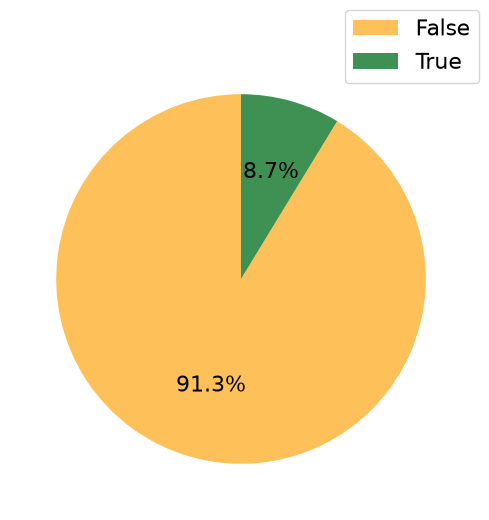

In [22]:
fig, ax = plot_pie_chart(data, variable="goal", colors=COLOR_MIX_YG)

There are far more shots that did not result in a goal than the other way around, making this dataset extremely **imbalanced**. Based on the context of this problem, it's not recommended to make goals and non-goals 50/50, because xG is fundamentally a probability-estimation problem. In xG, the aim of the model is to reproduce the **true probability distribution of scoring**. Therefore, if goals naturally occur on around 9% of shots, preserving that base rate is desirable. Nevertheless, there are some concerns to take into account during the model development:
- **A model can look good while being poor at identifying goals.** A classifier that predicts every shot as False would already achieve roughly 91.3% accuracy, so raw accuracy is almost useless here. Metrics such as **log loss**, **Brier score**, **ROC-AUC**, **PR-AUC**, **calibration curves**, and goal/non-goal **recall** are more informative.
- **The loss function is dominated by non-goals.** During training, there are roughly 10 non-goal examples for every goal, so errors on the majority class occur much more frequently. Some algorithms may consequently learn conservative probabilities or struggle to learn patterns associated with the relatively rare goal class.
- **Minority-class patterns can be harder to learn.** For example, headers from close range, one-on-ones, rebounds, and certain shot angles can have particularly high conversion probabilities. If some of those situations are rare, the model may have relatively little positive evidence from which to estimate their effects.
- **Threshold-based classification can be misleading.** Using the usual 0.5 cutoff, almost no shots should be classified as goals because most individual shots genuinely have an xG well below 0.5. For an xG model, that is not necessarily a problem: the important output is something like 0.04, 0.18, or 0.63, not whether the model predicts goal/non-goal at a fixed threshold.
- **Calibration becomes especially important.** If you assign 0.10 xG to 1,000 similar shots, you want approximately 100 of them to become goals. A model can have good ranking ability—high AUC—but systematically output probabilities that are too high or too low. For xG, that would be a significant problem.

##### Coordinates

###### `x`

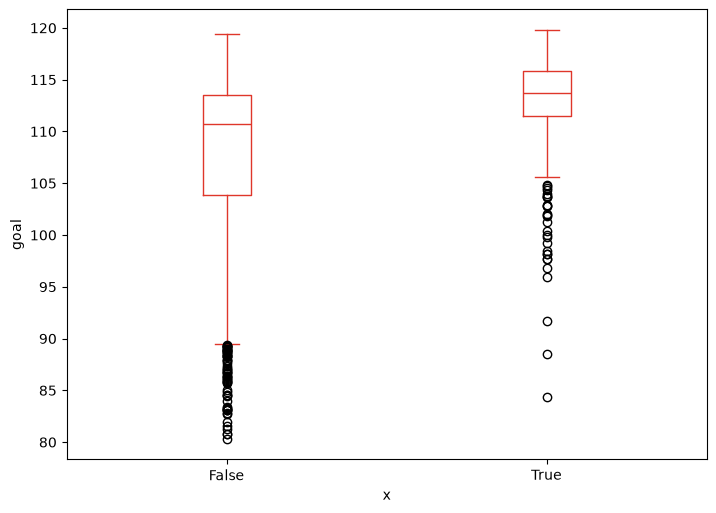

In [23]:
fig, ax = plot_grouped_boxplot(data, "x", "goal", color=COLOR_R)

In accordance with the shot map, the boxplot shows that **goals tend to occur at higher x-values** than non-goals. The median x-coordinate for goals is at the level of the non-goals 3rd quartile. The goal group also has a **narrower distribution**, suggesting that successful shots are more concentrated closer to goal. Both groups contain low-x outliers, representing shots taken from unusually long distances. Overall, **x-position appears to be a useful predictor of goal probability**.

###### `y`

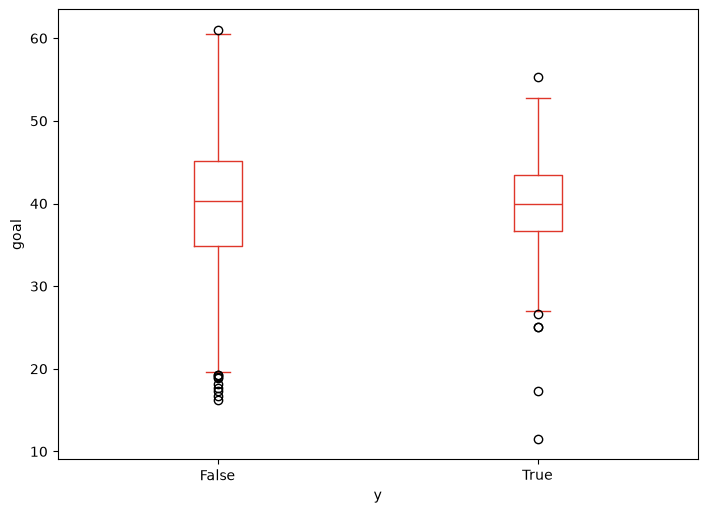

In [24]:
fig, ax = plot_grouped_boxplot(data, "y", "goal", color=COLOR_R)

**The median y-coordinate is almost identical** for goals and non-goals. However, goals have a **narrower distribution**, meaning they are more concentrated around the central area of the pitch. This suggests that **central shooting positions are more favorable**, while shots from wider y-positions are less likely to result in goals.

###### `z`

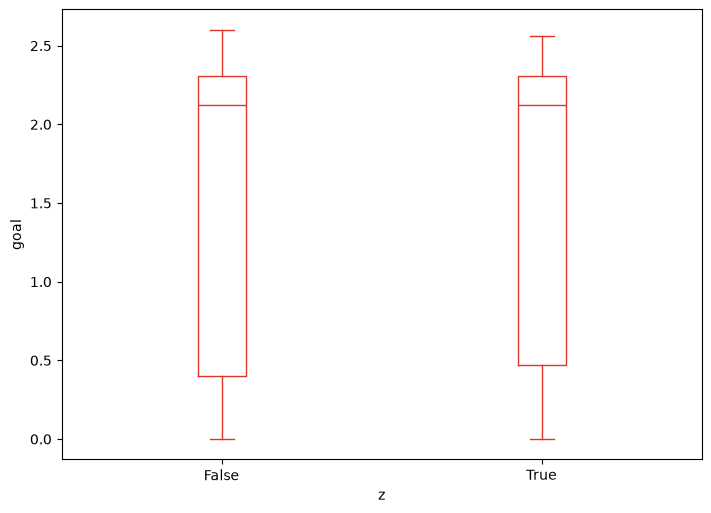

In [25]:
fig, ax = plot_grouped_boxplot(data, "z", "goal", color=COLOR_R)

**The distributions of z are almost identical** for goals and non-goals, with similar medians and spreads. Unlike the x and y coordinates, **z does not show a clear relationship with whether a shot results in a goal** when considered on its own.

##### Categorical context

###### `shot_body_part`

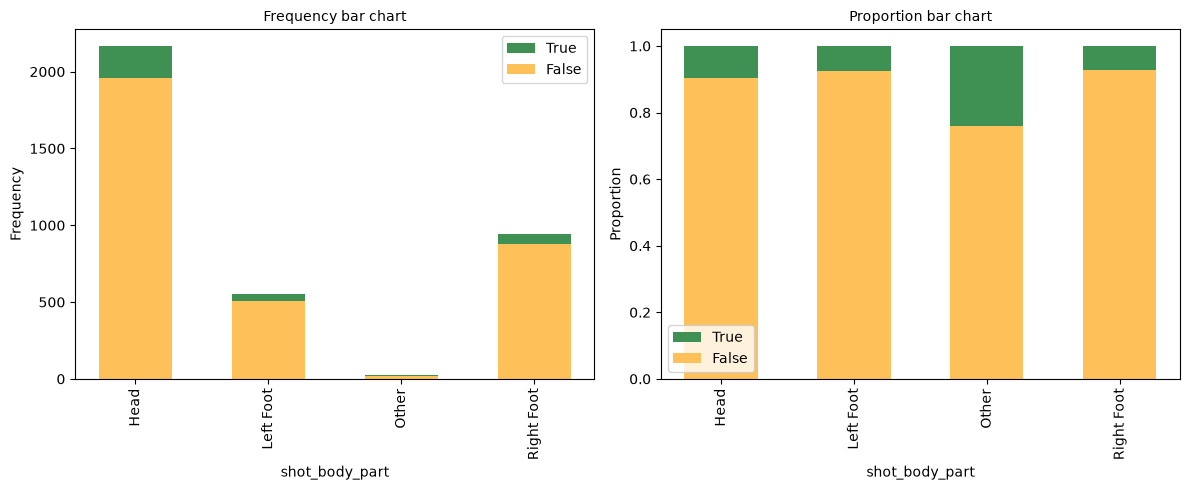

In [26]:
fig, (ax1, ax2) = plot_categorical_bar_charts(data, "shot_body_part", "goal", COLOR_MIX_YG)

Most shots are taken with the **head** or **right foot**, while left-footed shots are less frequent. The goal proportions for **head**, **left foot**, and **right foot** are relatively similar. The *Other* category shows a noticeably higher goal rate, but it contains very few observations, so this result should be interpreted cautiously. Overall, **shot body part may provide some predictive information**, but the differences between the main categories are fairly small.

In [27]:
data[["shot_body_part", "shot_technique"]].value_counts(dropna=False)

shot_body_part  shot_technique
Head            Normal            2151
Right Foot      Half Volley        373
                Volley             297
Left Foot       Half Volley        254
Right Foot      Normal             236
Left Foot       Normal             157
                Volley             128
Other           Normal              25
Right Foot      Backheel            19
Head            Diving Header       16
Right Foot      Overhead Kick       15
Left Foot       Overhead Kick        6
                Backheel             5
Right Foot      Lob                  3
Name: count, dtype: int64

###### `shot_technique`

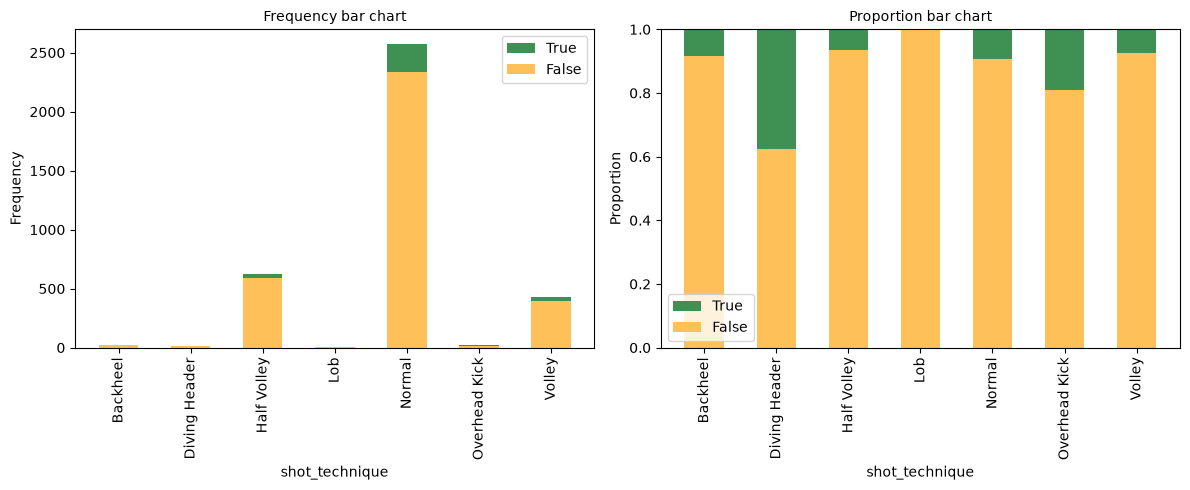

In [28]:
fig, (ax1, ax2) = plot_categorical_bar_charts(data, "shot_technique", "goal", COLOR_MIX_YG)

*Normal* shots dominate the dataset, followed by *Half Volley* and *Volley*. Most other techniques occur very rarely. Some rare categories, such as *Diving Header* and *Overhead Kick*, show high goal rates, but their **small sample sizes make these proportions unreliable**. To reduce complexity, the **rare techniques into an *Other* category**, while keeping *Normal*, *Half Volley*, and *Volley* separate.

###### `shot_first_time`

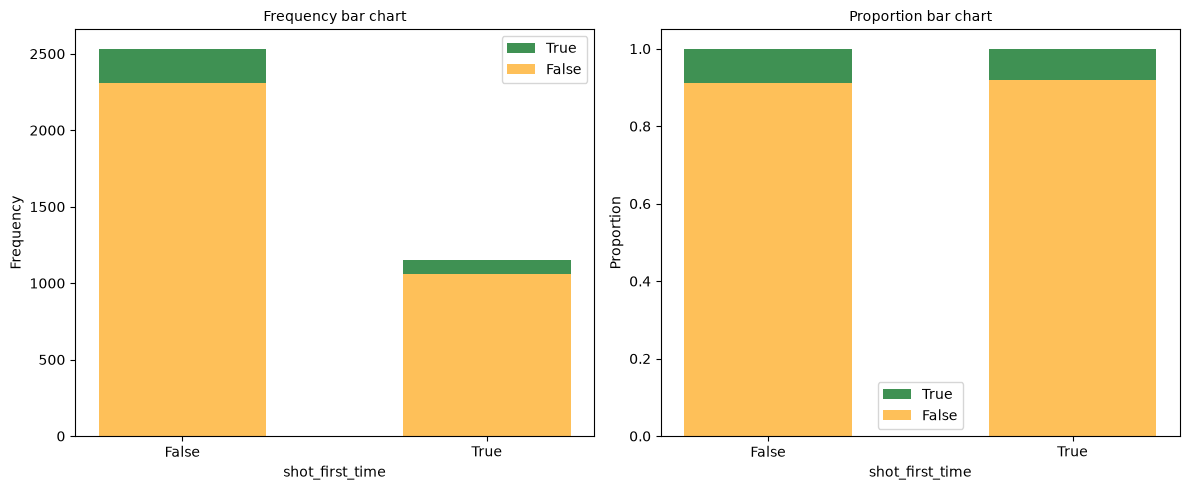

In [29]:
fig, (ax1, ax2) = plot_categorical_bar_charts(data, "shot_first_time", "goal", COLOR_MIX_YG)

First-time and non-first-time shots have **very similar goal rates**, although first-time shots appear to have a slightly lower conversion rate. Both categories contain many observations, but its **individual predictive power appears limited** from this graph.

###### `shot_one_on_one`

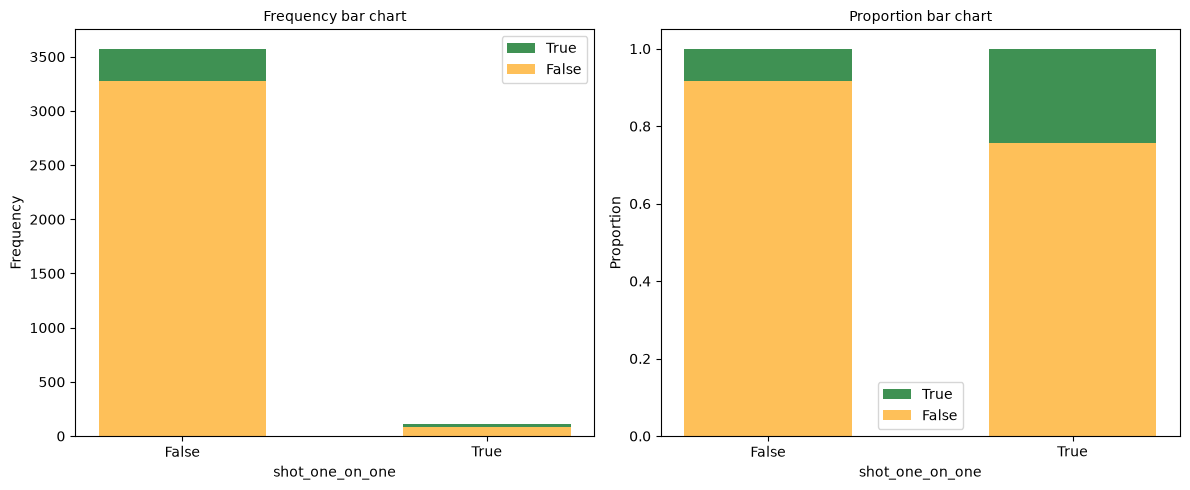

In [30]:
fig, (ax1, ax2) = plot_categorical_bar_charts(data, "shot_one_on_one", "goal", COLOR_MIX_YG)

One-on-one shots are **very rare**, but they have a substantially higher goal rate compared with non-one-on-one shots. At an early stage, its **individual predictive power is a bit dubious**.

###### `shot_open_goal`

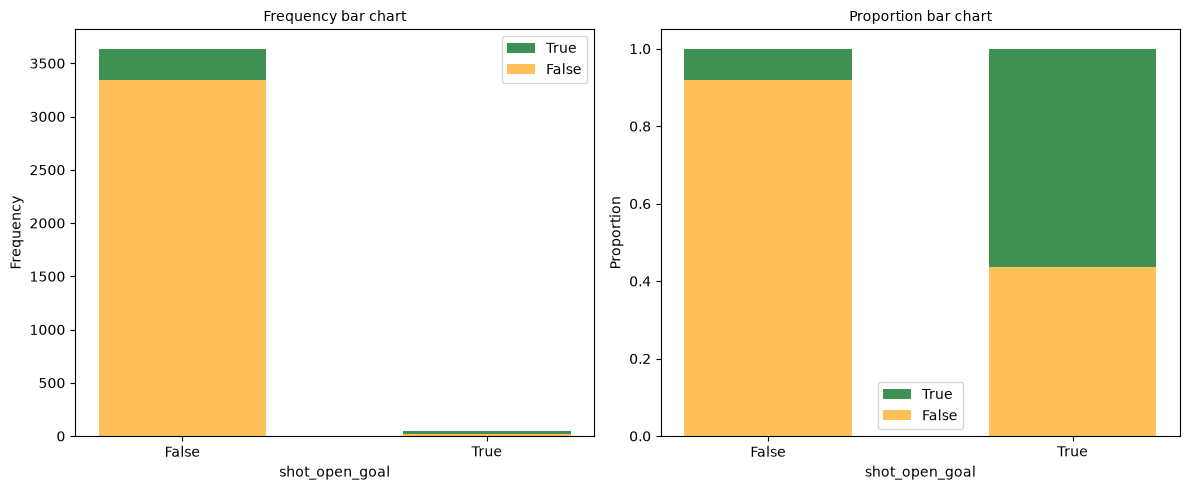

In [31]:
fig, (ax1, ax2) = plot_categorical_bar_charts(data, "shot_open_goal", "goal", COLOR_MIX_YG)

Open-goal shots **are very rare**, but they have a much higher conversion rate than regular shots. Despite its low frequency, it can have a great individual predictive power.

###### `shot_follows_dribble`

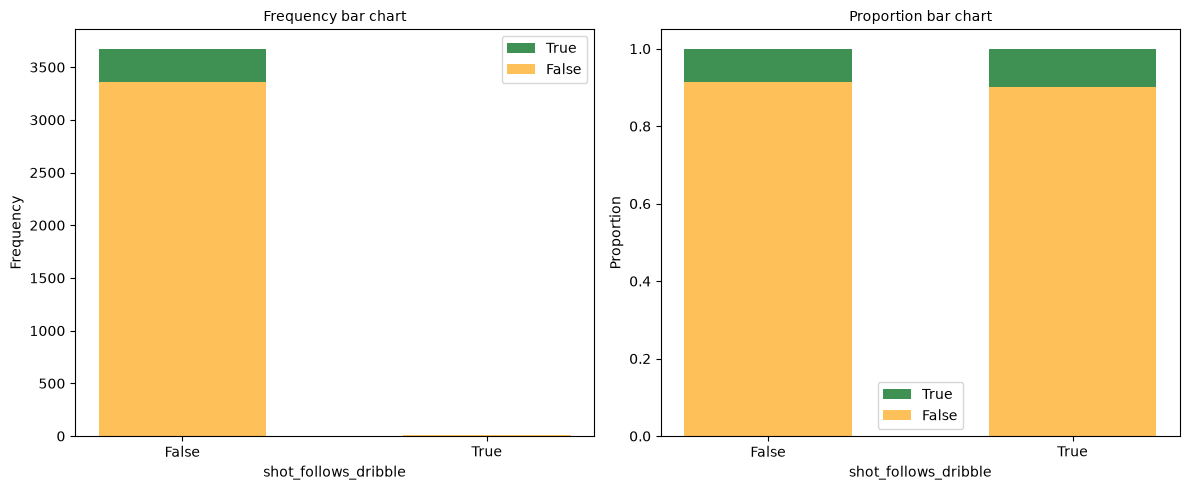

In [32]:
fig, (ax1, ax2) = plot_categorical_bar_charts(data, "shot_follows_dribble", "goal", COLOR_MIX_YG)

Shots following a dribble are **extremely rare** in the dataset. Their goal rate appears **slightly higher** than that of other shots, but **the sample size is too small** to draw strong conclusions. It does not appear to have individual predictive power.

###### `shot_from_corner`

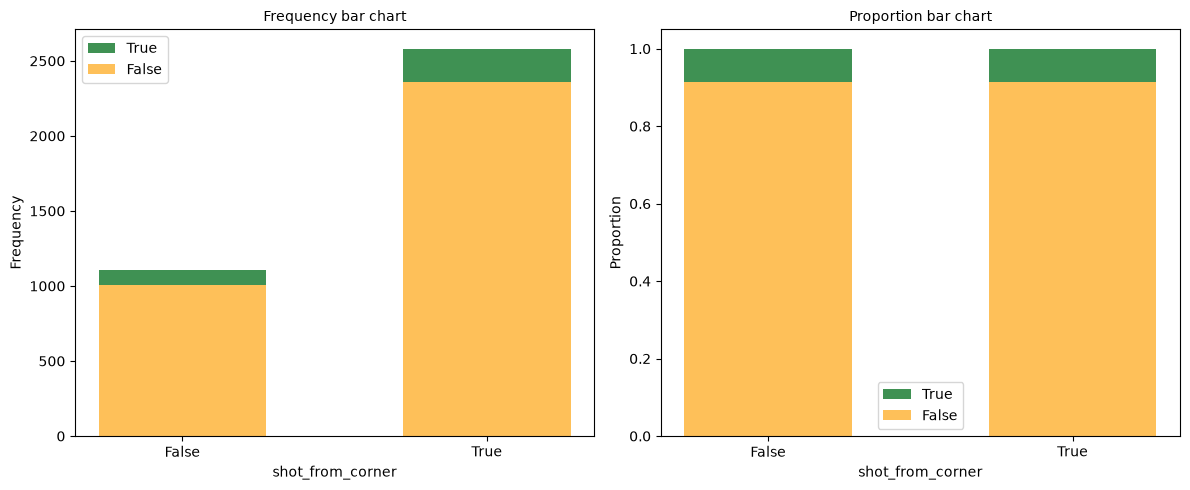

In [33]:
fig, (ax1, ax2) = plot_categorical_bar_charts(data, "shot_from_corner", "goal", COLOR_MIX_YG)

Shots originating from corners have a **very similar goal rate** to shots from other situations, with only a small difference between the two groups. The graph suggests it may have limited predictive power on its own.

###### `shot_aerial_won`

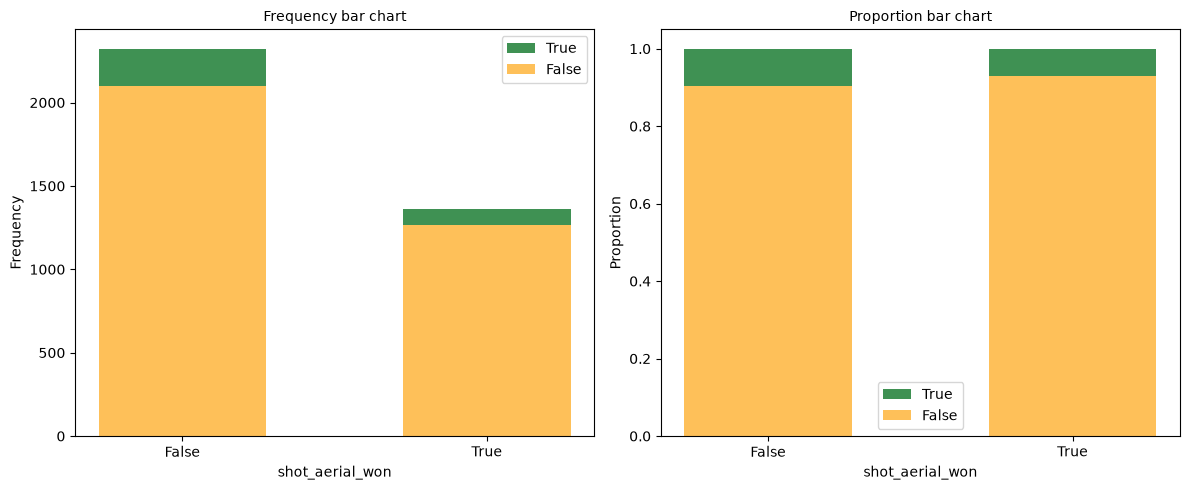

In [34]:
fig, (ax1, ax2) = plot_categorical_bar_charts(data, "shot_aerial_won", "goal", COLOR_MIX_YG)

Shots where an aerial duel was won have a **slightly lower goal rate** than shots without an aerial duel won. Both categories have a large number of observations and the graph suggests its **individual predictive power is moderate**.

###### `shot_assisted`

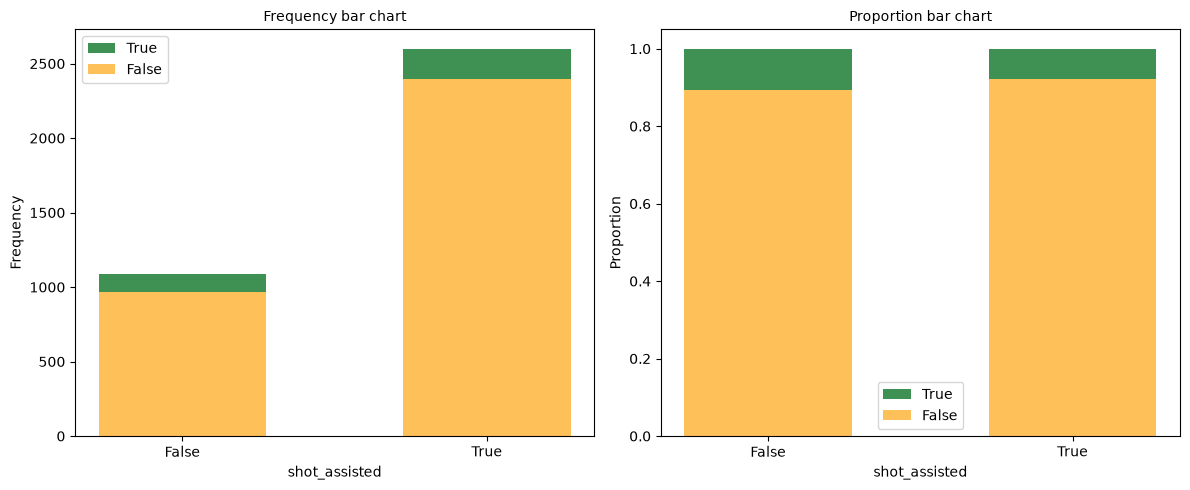

In [35]:
fig, (ax1, ax2) = plot_categorical_bar_charts(data, "shot_assisted", "goal", COLOR_MIX_YG)

Assisted shots are much more common in the dataset, but **their goal rate is slightly lower than** that of unassisted shots. The difference is relatively small, but it appears to have **moderate predictive power** on its own.

###### `under_pressure`

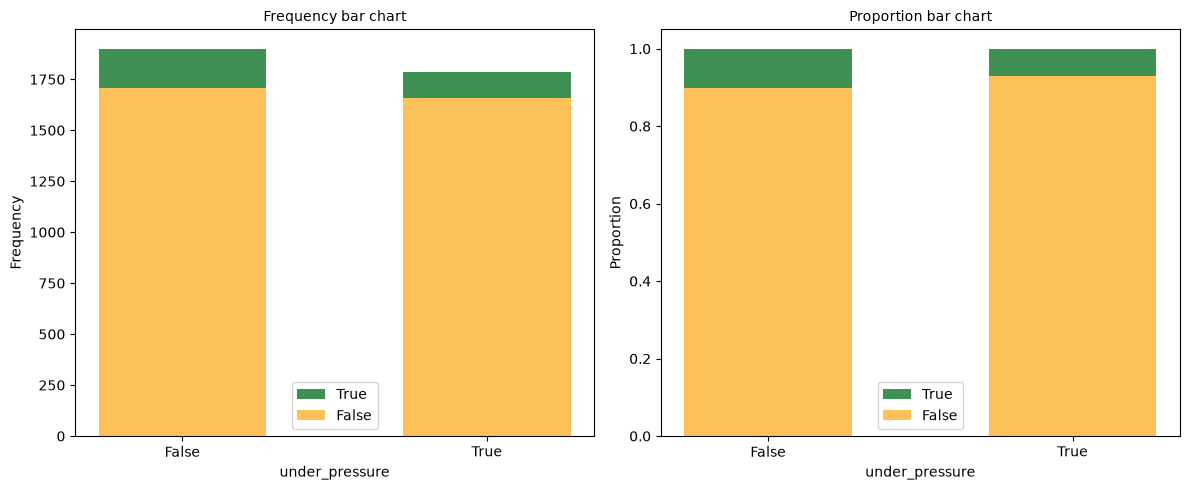

In [36]:
fig, (ax1, ax2) = plot_categorical_bar_charts(data, "under_pressure", "goal", COLOR_MIX_YG)

Shots taken under pressure have a **lower goal rate** than shots taken without pressure. Both groups contain many observations, and the difference in conversion rate is noticeable. It appears to provide useful information for predicting goal probability; in other words, **moderate individual predictive value**.

##### From freeze frame

###### `shot_distance_to_goal`

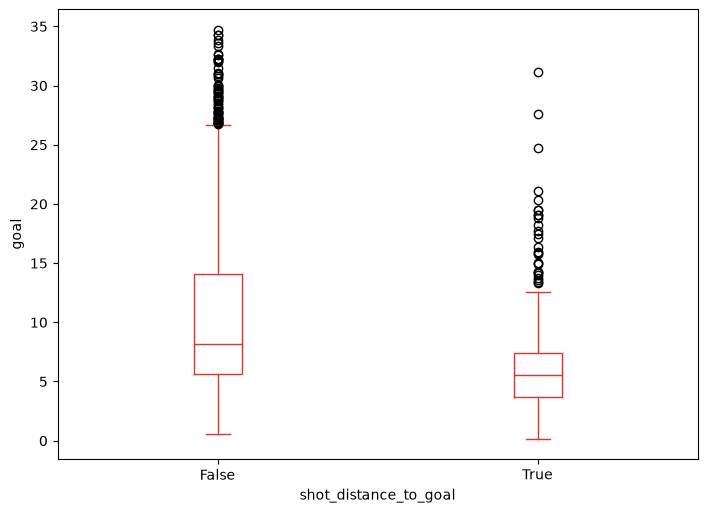

In [37]:
fig, ax = plot_grouped_boxplot(data, "shot_distance_to_goal", "goal", color=COLOR_R)

Goals are generally scored from **shorter distances**, with the median distance noticeably lower for goals than for non-goals. Although there is some overlap and a few long-distance goals, the pattern is clear: **goal probability decreases as shot distance increases**. It is **likely to be one of the most important predictors** in the xG model.

###### `shot_distance_to_goal_center`

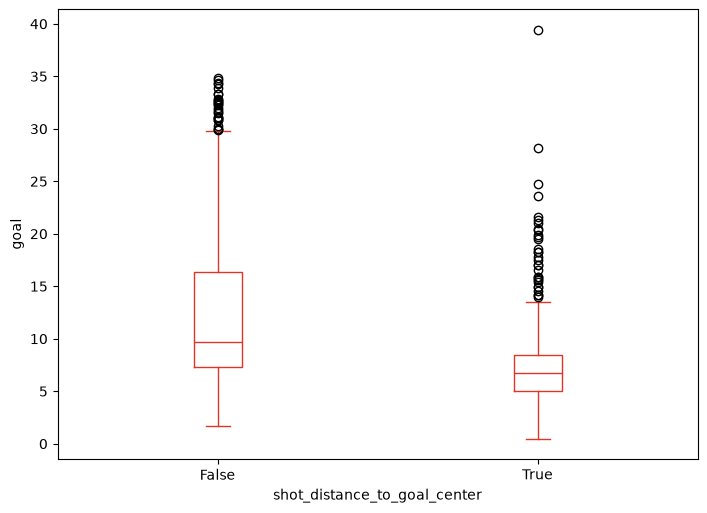

In [38]:
fig, ax = plot_grouped_boxplot(data, "shot_distance_to_goal_center", "goal", color=COLOR_R)

Goals are generally scored from **shorter distances to the center of the goal**, with a clearly lower median than non-goals. The separation between the two groups is noticeable, suggesting that it is likely to be a **strong predictor of goal probability**. Since this variable is probably highly correlated with `shot_distance_to_goal`, the correlation between them should be checked before including both.

###### `nearest_defender_1_distance`

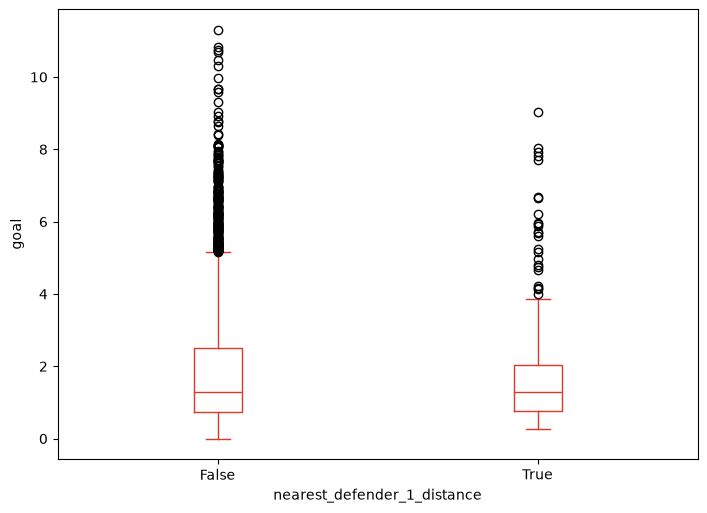

In [39]:
fig, ax = plot_grouped_boxplot(data, "nearest_defender_1_distance", "goal", color=COLOR_R)

The median distance to the nearest defender is **very similar for goals and non-goals**. However, goals show a somewhat narrower distribution, with fewer shots taken when the nearest defender is very far away. On its own, this variable does **not show strong separation** between goals and non-goals.

###### `nearest_defender_2_distance`

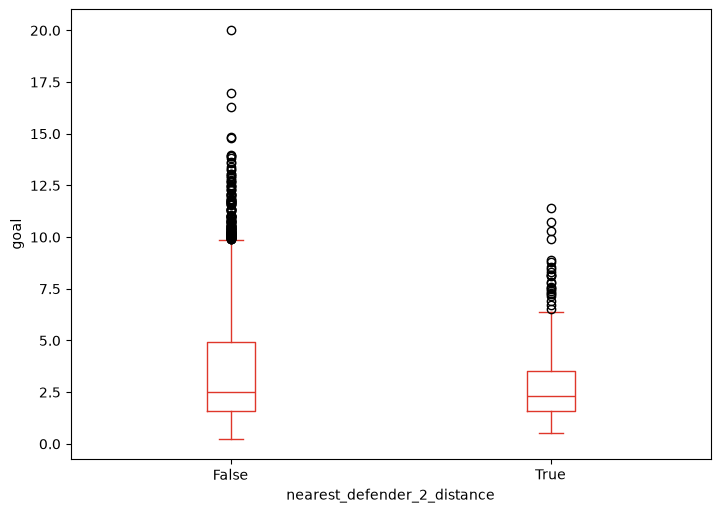

In [40]:
fig, ax = plot_grouped_boxplot(data, "nearest_defender_2_distance", "goal", color=COLOR_R)

The second nearest defender tends to be **slightly closer for goals than for non-goals**, although there is considerable overlap between the groups. It shows **some potential predictive value**, but the relationship is not particularly strong on its own. It's important to check for high correlation with `nearest_defender_1_distance`.

###### `nearest_defender_3_distance`

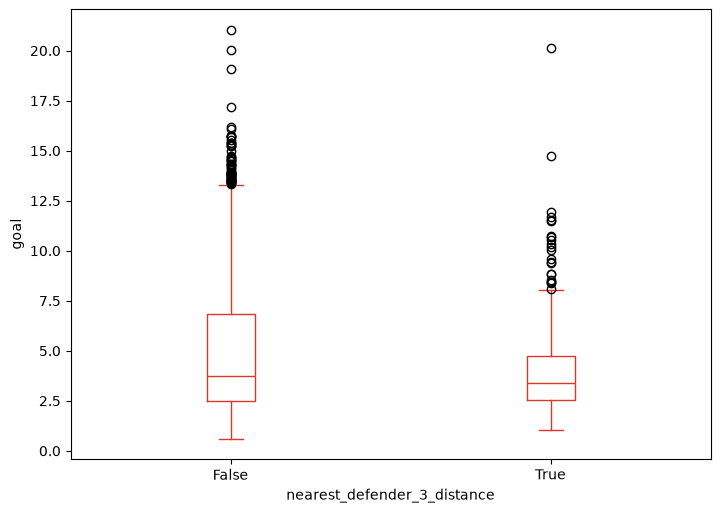

In [41]:
fig, ax = plot_grouped_boxplot(data, "nearest_defender_3_distance", "goal", color=COLOR_R)

The third nearest defender tends to be **slightly closer for goals**, but there is substantial overlap between goals and non-goals. It may provide some predictive information, although it's important to **check its correlation with the first and second nearest-defender distances**, as these three variables could contain redundant information.

###### `defenders_within_1m`

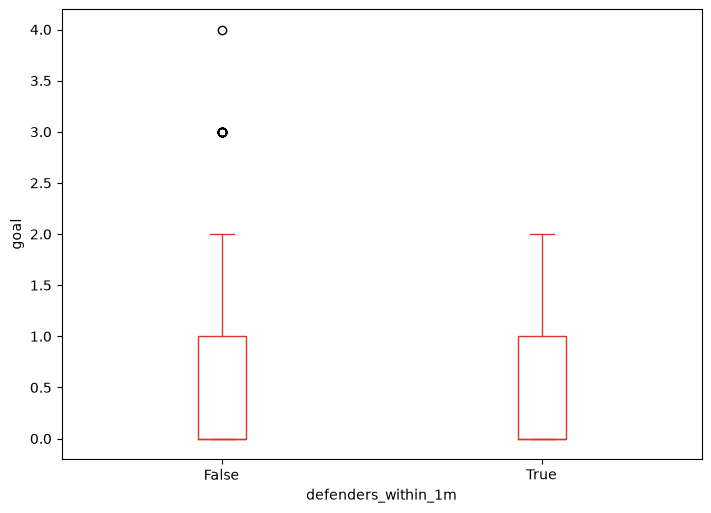

In [42]:
fig, ax = plot_grouped_boxplot(data, "defenders_within_1m", "goal", color=COLOR_R)

The distributions are **almost identical for goals and non-goals**, suggesting that it has **limited predictive power** on its own. The nearest-defender distance variables already potentially capture the same defensive-pressure information.

###### `defenders_within_3m`

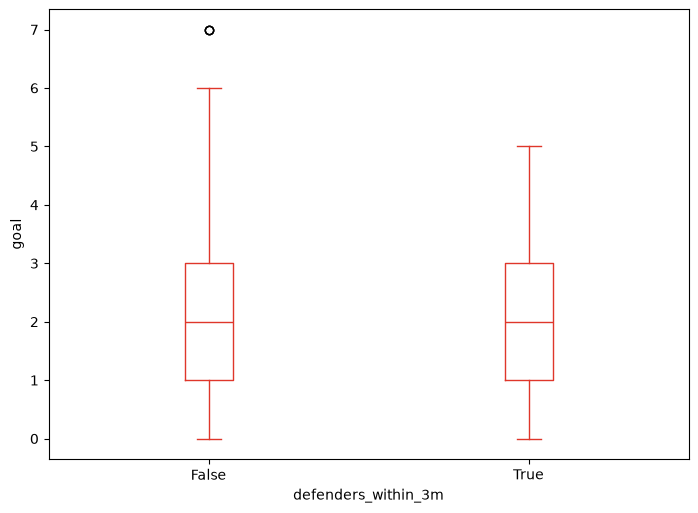

In [43]:
fig, ax = plot_grouped_boxplot(data, "defenders_within_3m", "goal", color=COLOR_R)

The distributions are **almost identical for goals and non-goals**, with the same median and very similar spread. This suggests that it has **little predictive power** on its own.

###### `defenders_within_5m`

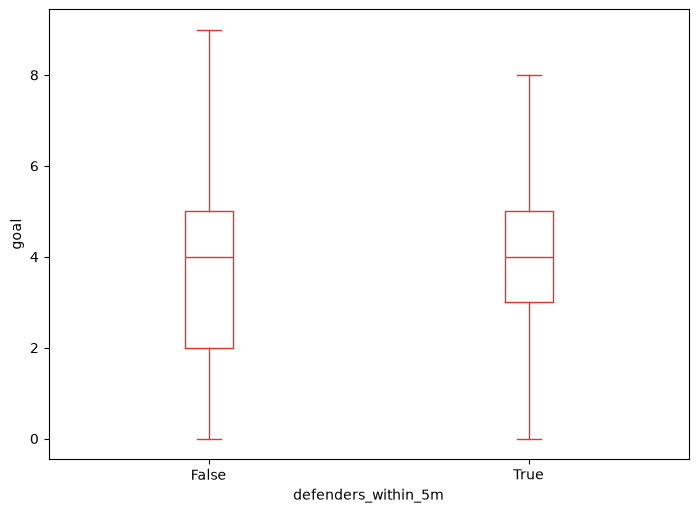

In [44]:
fig, ax = plot_grouped_boxplot(data, "defenders_within_5m", "goal", color=COLOR_R)

The distributions for goals and non-goals are **very similar**, with the same median and considerable overlap. This suggests that it has **limited predictive power** on its own. Given the similar conclusions for defenders within 1m and 3m, these variables may also be redundant.

###### `defenders_in_shot_triangle`

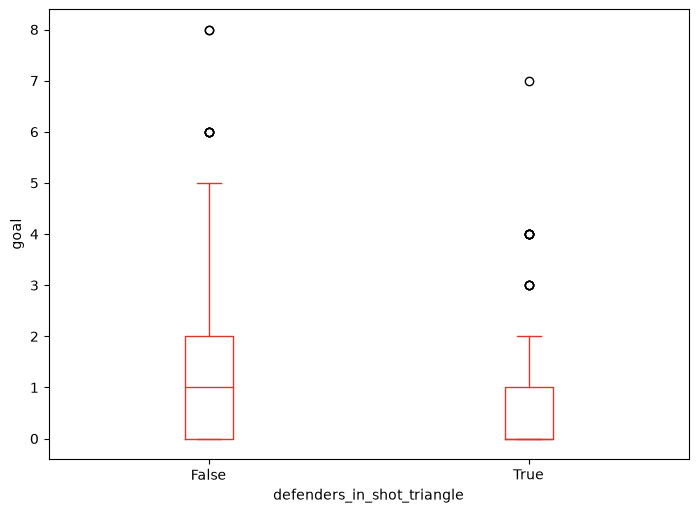

In [45]:
fig, ax = plot_grouped_boxplot(data, "defenders_in_shot_triangle", "goal", color=COLOR_R)

Goals tend to have **fewer defenders in the shot triangle**, with the goal group concentrated more strongly around 0–1 defenders. This suggests the variable captures **useful information** about how obstructed the path to goal is.

###### `closest_defender_in_shot_triangle`

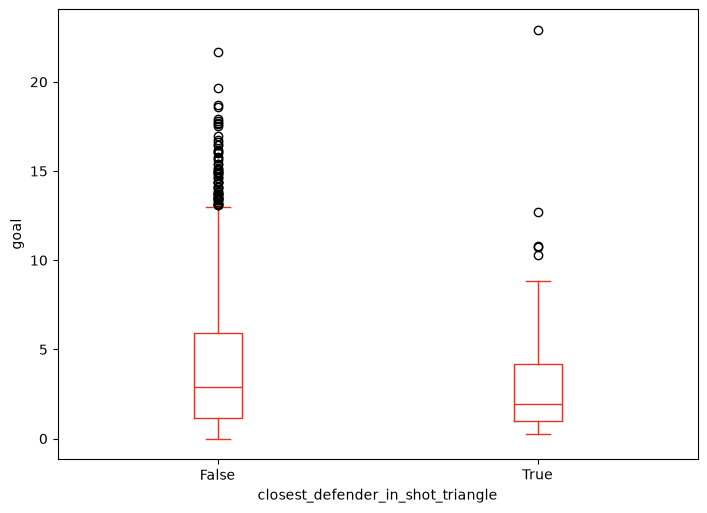

In [46]:
fig, ax = plot_grouped_boxplot(data, "closest_defender_in_shot_triangle", "goal", color=COLOR_R)

Goals tend to occur when the **closest defender in the shot triangle is nearer**, with a lower median distance than for non-goals. There is still considerable overlap between the groups, but the variable shows some separation. It adds information about defender positioning within the actual shooting path, so it appears to have a **good individual predictive power**.

###### `avg_distance_defenders_in_triangle`

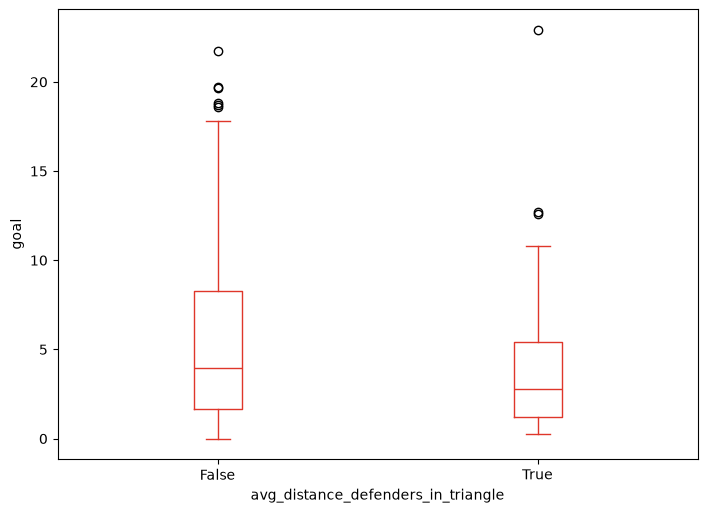

In [47]:
fig, ax = plot_grouped_boxplot(data, "avg_distance_defenders_in_triangle", "goal", color=COLOR_R)

Goals tend to have a **lower average defender distance** within the shot triangle than non-goals, although there is substantial overlap. The variable shows some separation and may provide useful information. It's important ti check its correlation with `closest_defender_in_shot_triangle` since the two may capture similar information.

###### `open_goal_angle`

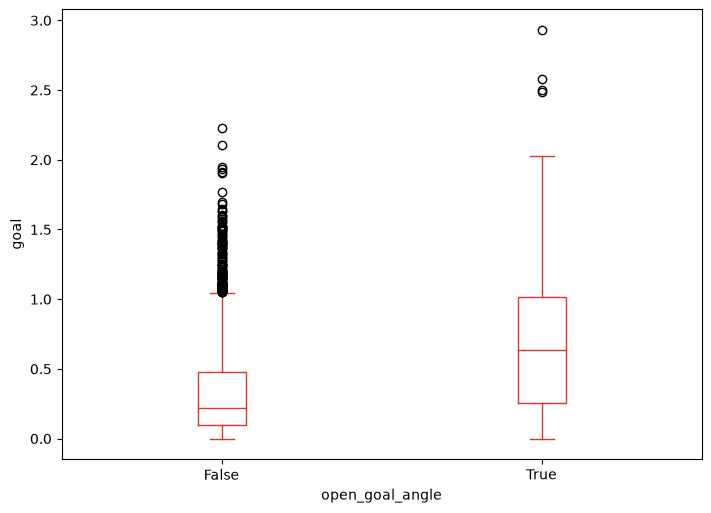

In [48]:
fig, ax = plot_grouped_boxplot(data, "open_goal_angle", "goal", color=COLOR_R)

Goals have a **clearly larger open-goal angle** than non-goals, with a substantially higher median and wider distribution. This shows a strong relationship with scoring probability: **the more of the goal that is open to the shooter, the greater the likelihood of scoring**. It appears to be a strong predictor for the xG model.

###### `blocked_goal_angle`

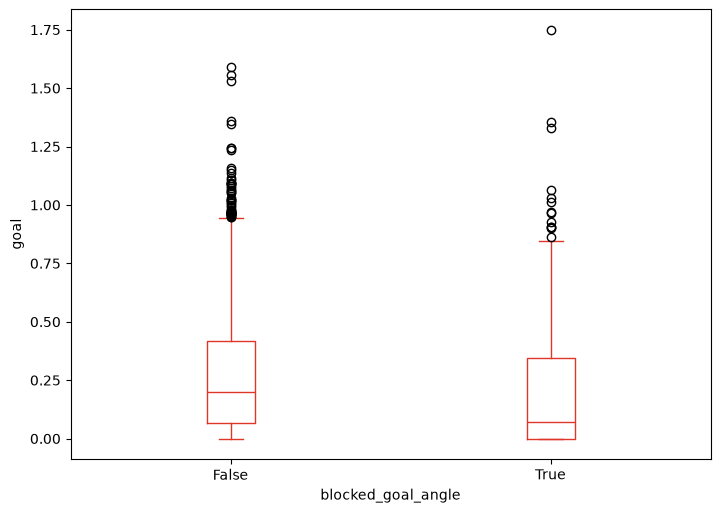

In [49]:
fig, ax = plot_grouped_boxplot(data, "blocked_goal_angle", "goal", color=COLOR_R)

Goals generally have a **smaller blocked-goal angle** than non-goals, with a noticeably lower median. This suggests that **less obstruction of the goal is associated with a higher scoring probability**.

###### `fraction_goal_angle_blocked`

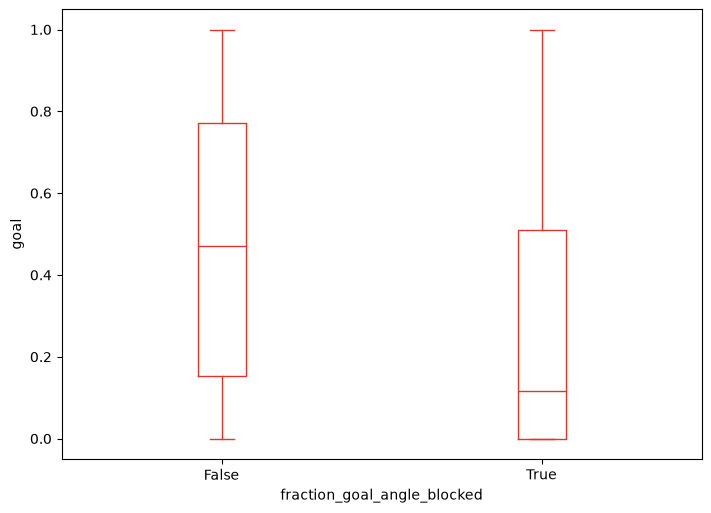

In [50]:
fig, ax = plot_grouped_boxplot(data, "fraction_goal_angle_blocked", "goal", color=COLOR_R)

Goals generally have a **much lower fraction of the goal angle blocked** than non-goals, with a clearly lower median. This suggests a strong relationship with scoring probability: **the less of the available goal angle that is blocked, the more likely the shot is to result in a goal**. Although the visual distributions are different, redundancy with `open_goal_angle` and `blocked_goal_angle` needs to be check.

###### `gk_distance_to_ball`

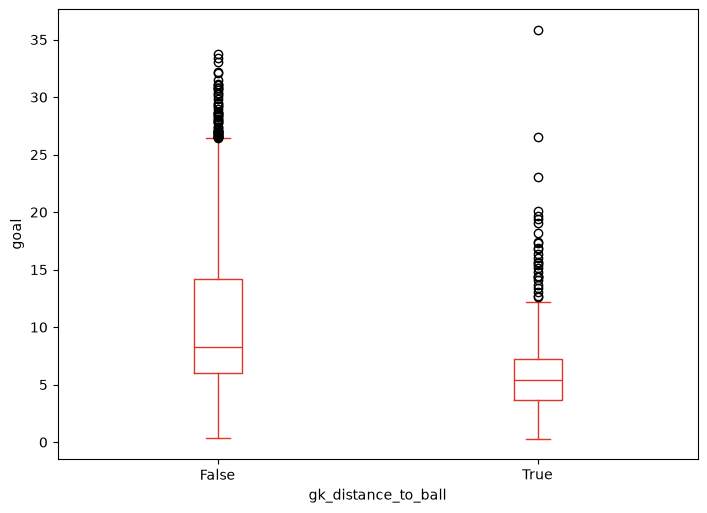

In [51]:
fig, ax = plot_grouped_boxplot(data, "gk_distance_to_ball", "goal", color=COLOR_R)

Goals tend to occur when the **goalkeeper is closer to the ball**, with a noticeably lower median distance compared with non-goals. The distributions still overlap, but the separation is fairly clear. The goalkeeper-to-ball distance appears to contain **useful individual predictive information** for the xG model.

###### `gk_distance_to_goal`

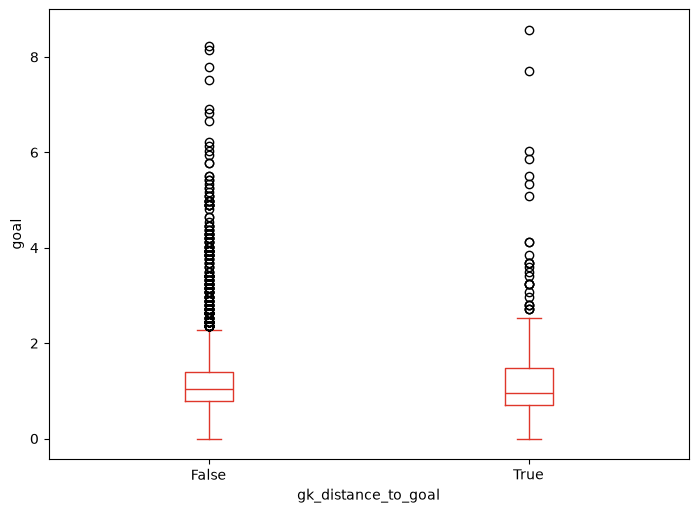

In [52]:
fig, ax = plot_grouped_boxplot(data, "gk_distance_to_goal", "goal", color=COLOR_R)

The goalkeeper's distance to goal is **very similar for goals and non-goals**, with substantial overlap between the two distributions. On its own, it appears to have **limited predictive power**. The goalkeeper positioning could become more informative when combined with shot location or angle.

###### `gk_distance_to_goal_center`

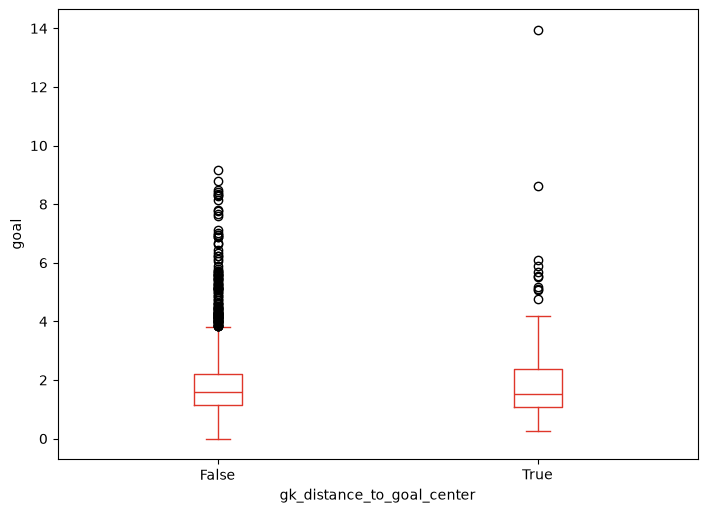

In [53]:
fig, ax = plot_grouped_boxplot(data, "gk_distance_to_goal_center", "goal", color=COLOR_R)

The goalkeeper's distance to the goal center is **very similar for goals and non-goals**, with almost identical medians and substantial overlap. On its own, this variable appears to have **limited predictive power**.

###### `gk_distance_to_shot_centerline`

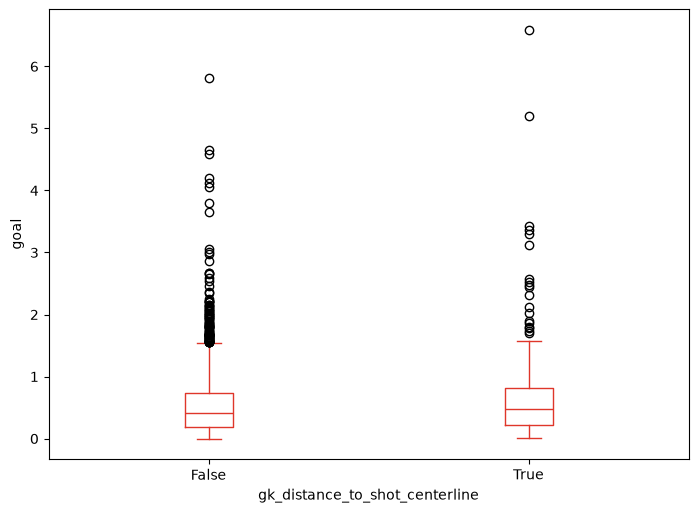

In [54]:
fig, ax = plot_grouped_boxplot(data, "gk_distance_to_shot_centerline", "goal", color=COLOR_R)

The distributions are **very similar for goals and non-goals**, although goals have a slightly higher median. There is substantial overlap, suggesting that it has **limited predictive power** on its own. However, it can add useful information alongside the other goalkeeper-positioning variables.

###### `gk_lateral_position`

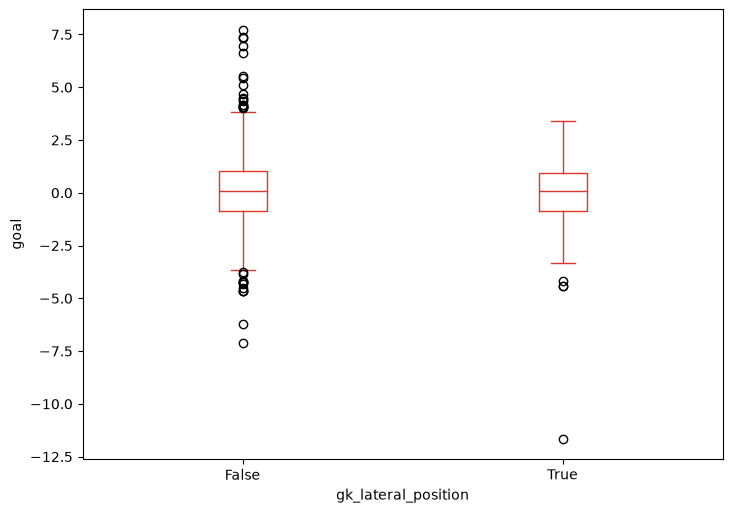

In [55]:
fig, ax = plot_grouped_boxplot(data, "gk_lateral_position", "goal", color=COLOR_R)

The distributions are **almost identical for goals and non-goals**, with both centered around zero and showing substantial overlap. This suggests that it has **limited predictive power** on its own, but it may become more informative when combined with the shot's lateral position or shooting angle.

###### `gk_goal_angle_coverage`

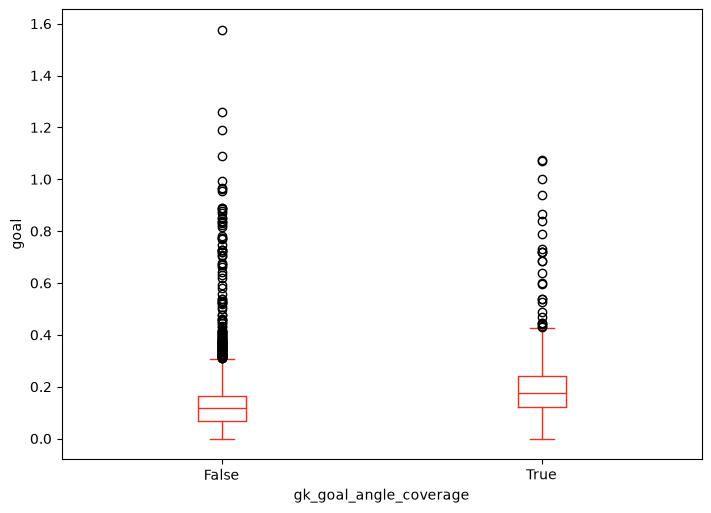

In [56]:
fig, ax = plot_grouped_boxplot(data, "gk_goal_angle_coverage", "goal", color=COLOR_R)

Goals tend to have **higher goalkeeper goal-angle coverage**, with a noticeably higher median than non-goals. This suggests the variable contains **useful information** about goalkeeper positioning. It's important to check its correlation with other angle-related features such as `open_goal_angle` and `fraction_goal_angle_blocked` to avoid redundancy.

###### `nearest_teammate_1_distance`

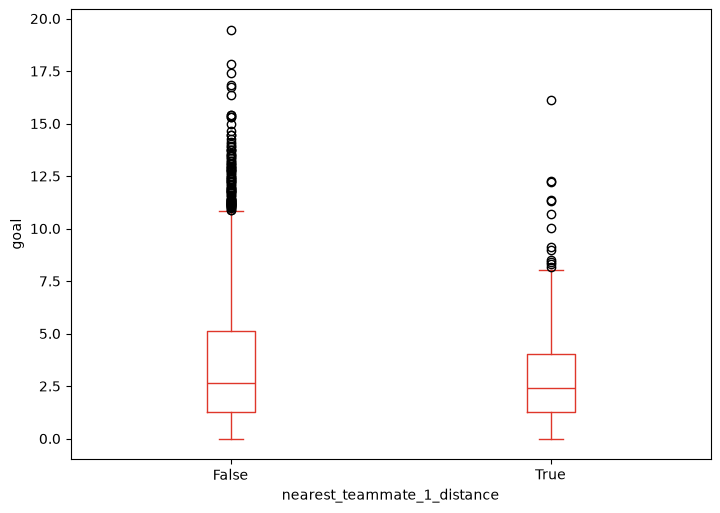

In [57]:
fig, ax = plot_grouped_boxplot(data, "nearest_teammate_1_distance", "goal", color=COLOR_R)

Goals tend to occur when the **nearest teammate is slightly closer**, with a lower median and narrower distribution than for non-goals. However, there is substantial overlap between the groups, so the variable shows **moderate predictive potential rather than a strong relationship**.

###### `nearest_teammate_2_distance`

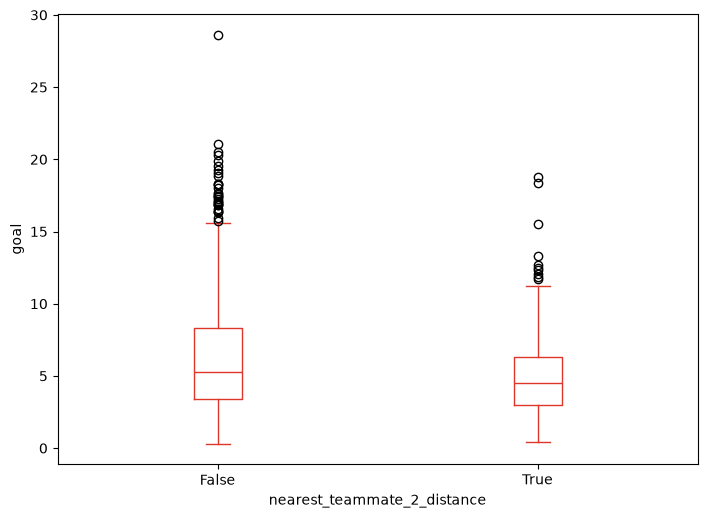

In [58]:
fig, ax = plot_grouped_boxplot(data, "nearest_teammate_2_distance", "goal", color=COLOR_R)

Goals tend to occur when the **second nearest teammate is slightly closer**, with a lower median than for non-goals. However, there is considerable overlap between the groups. The correlation with `nearest_teammate_1_distance` should be checked, as the two variables may contain redundant information.

###### `nearest_teammate_3_distance`

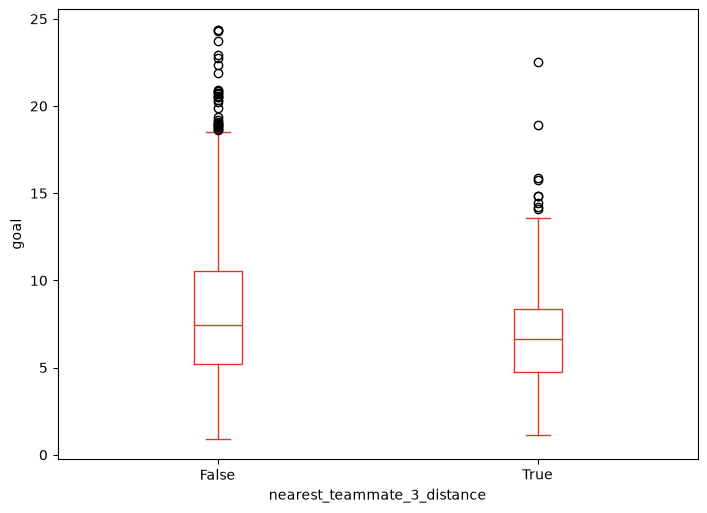

In [59]:
fig, ax = plot_grouped_boxplot(data, "nearest_teammate_3_distance", "goal", color=COLOR_R)

Goals tend to have a **slightly shorter distance to the third nearest teammate**, although there is substantial overlap between both groups. The variable may provide **some predictive information**, but redundancy with the first and second nearest-teammate distances needs to be checked before keeping all three.

###### `teammates_within_1m`

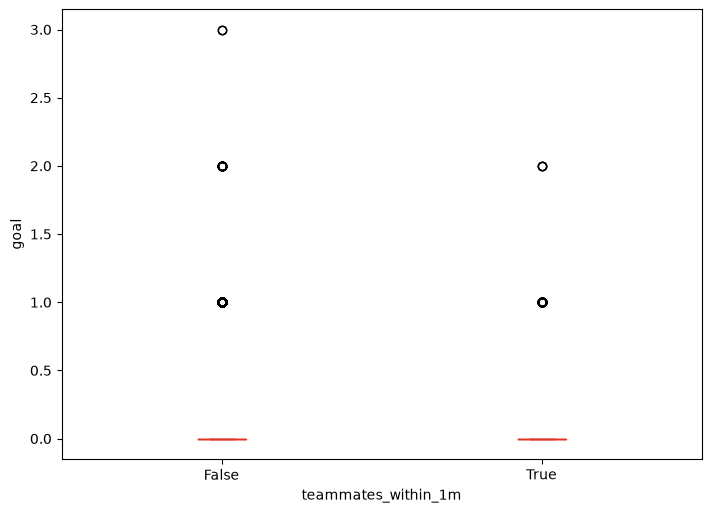

In [60]:
fig, ax = plot_grouped_boxplot(data, "teammates_within_1m", "goal", color=COLOR_R)

Almost all shots have **zero teammates within 1 metre**, for both goals and non-goals. The distributions show virtually no difference between the two outcomes. It has very low variation and does **not appear to provide useful predictive information**.

###### `teammates_within_3m`

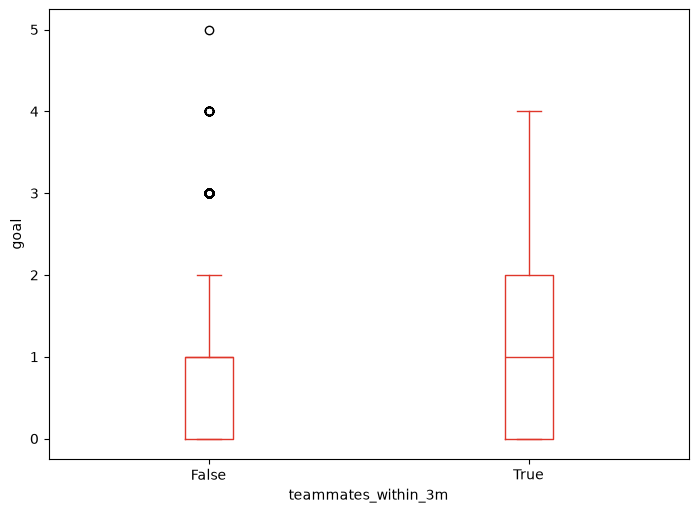

In [61]:
fig, ax = plot_grouped_boxplot(data, "teammates_within_3m", "goal", color=COLOR_R)

Goals tend to have **more teammates within 3 metres**, with a median of around 1 compared with 0 for non-goals. This suggests the variable may capture **useful attacking context**. Its relationship with the nearest-teammate distance variables should be checked for redundancy.

###### `teammates_within_5m`

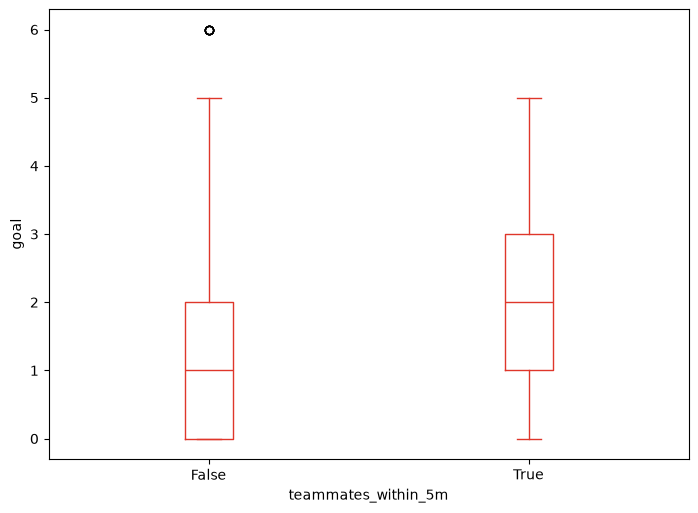

In [62]:
fig, ax = plot_grouped_boxplot(data, "teammates_within_5m", "goal", color=COLOR_R)

Goals tend to have **more teammates within 5 metres**, with a median of around 2 compared with 1 for non-goals. The difference between the groups is noticeable, suggesting this variable has **useful predictive potential**. It's important to check its correlation with `teammates_within_3m` to avoid redundancy.

#### Multivariate

##### Correlation matrix

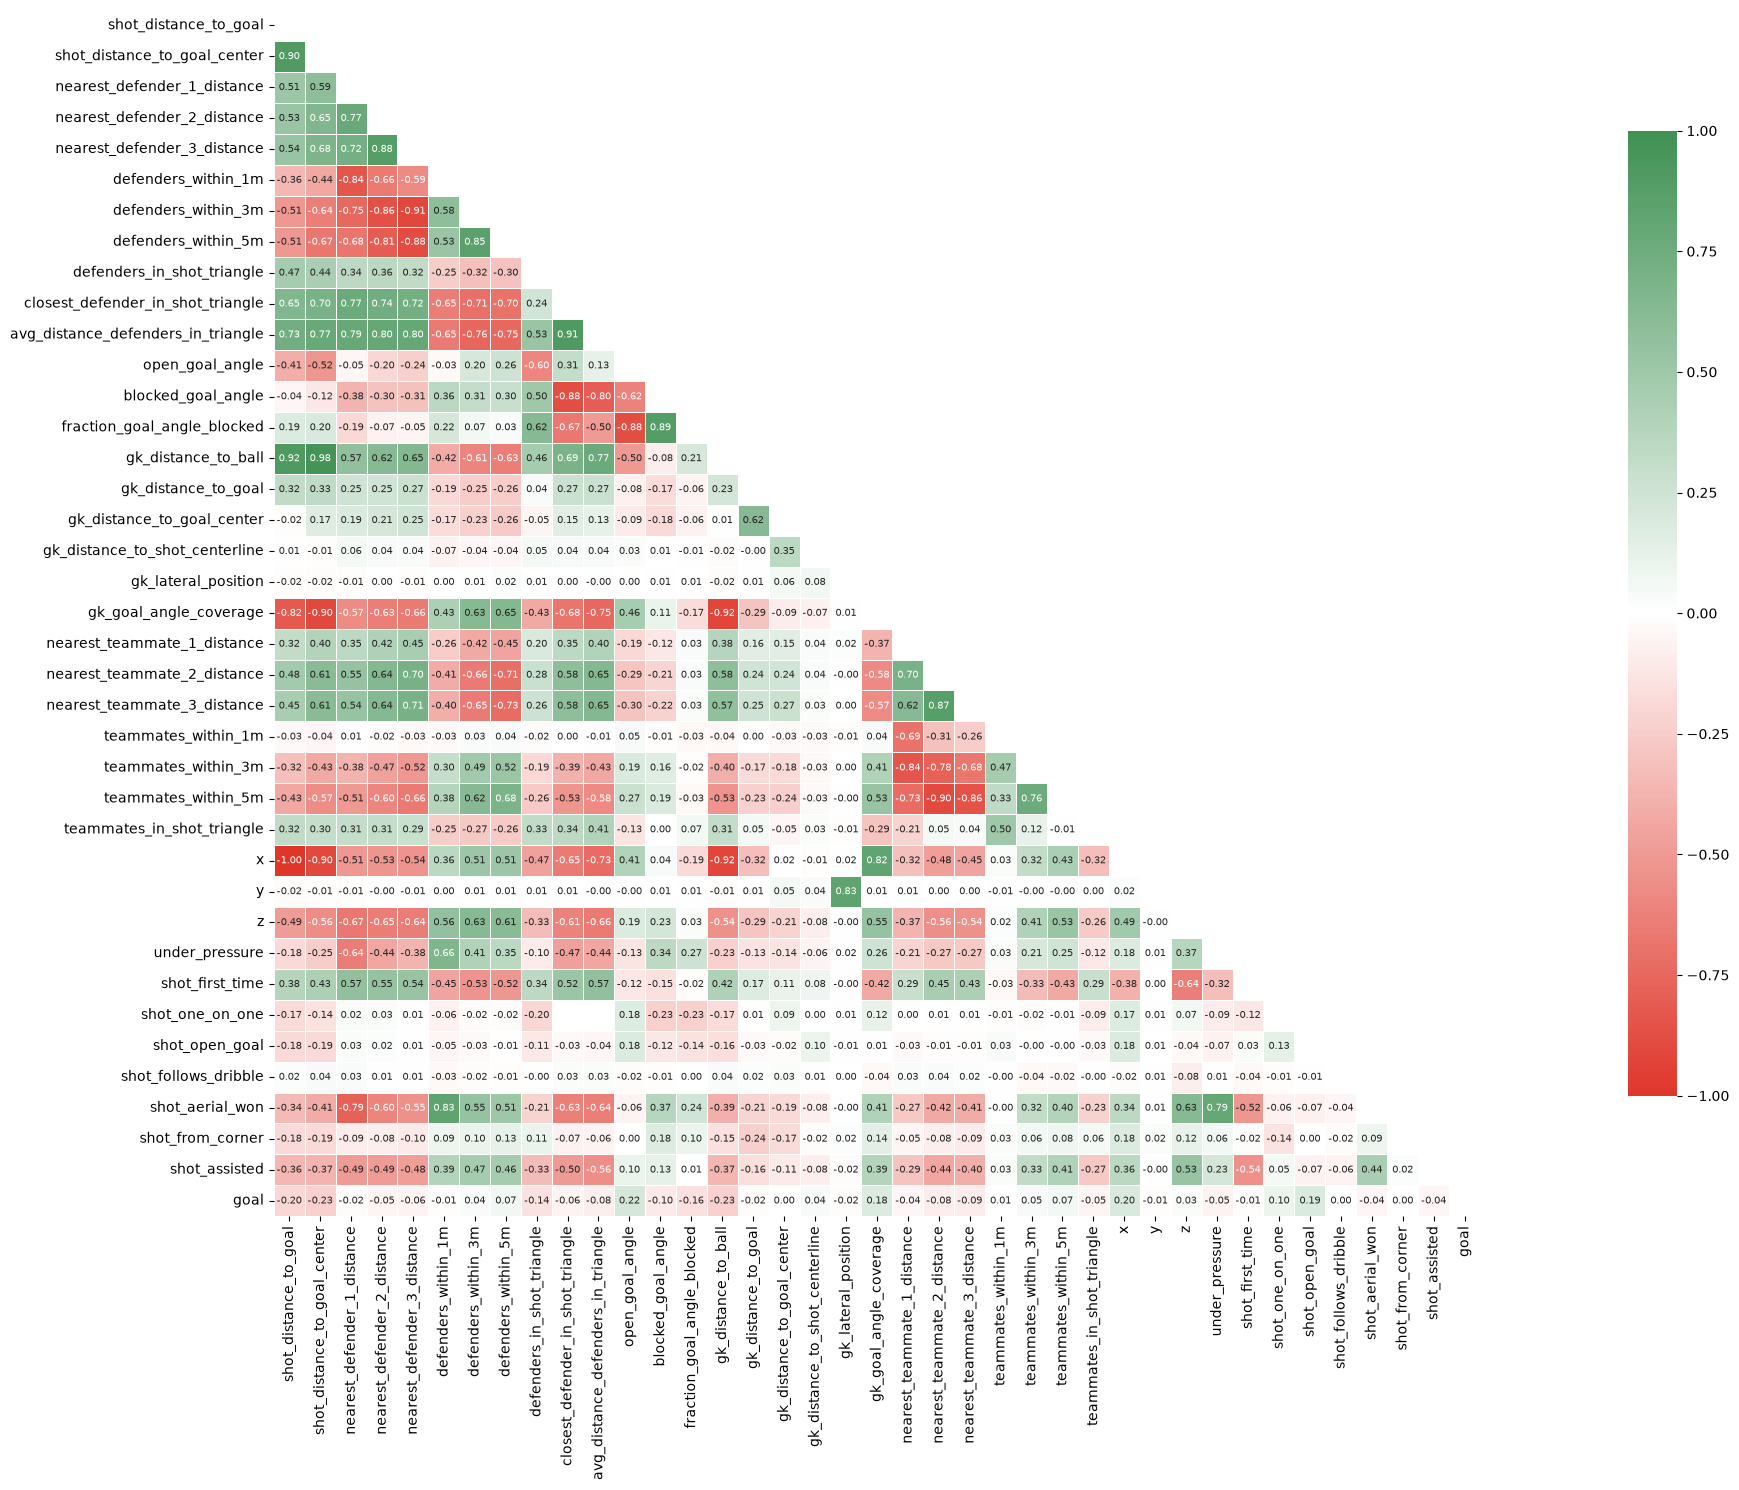

In [63]:
fig, ax = plot_correlation_matrix(
    data=data[numeric_cols + bool_cols + ["goal"]], method="spearman",
    mask_upper_triangle=True, color_map=custom_cmap_rwg, annot_fontsize=7.5, set_title=False
)

**Shot geometry variables are strongly interrelated.** `shot_distance_to_goal` and `shot_distance_to_goal_center` correlate at 0.90, and both correlate almost perfectly with `x` (1.00 and −0.90 respectively) and with `gk_distance_to_ball` (0.92 and 0.98). This is expected: a shot's position on the pitch largely determines its distance to goal, which in turn determines how far the goalkeepe naturally sits from the ball. These four variables are effectively encoding the same underlying geometric fact from slightly different angles.

**Defender-count and defender-distance variables form a tightly linked block.** `nearest_defender_1_distance`, `_2_distance`, and `_3_distance` correlate with each other at 0.72–0.88, while `defenders_within_1m`, `_3m`, and `_5m` correlate at 0.53–0.85 among themselves and show strong negative correlations (down to −0.91) with the nearest-defender distances. This confirms that shots closer to goal systematically attract more nearby defenders, so distance and defender-density variables are largely redundant descriptions of defensive pressure rather than independent phenomena. `closest_defender_in_shot_triangle` and `avg_distance_defenders_in_triangle` correlate at 0.91 with each other and 0.70–0.80 with the broader defender-distance group, reinforcing this redundancy.

**Goalkeeper positioning variables cluster around shot distance.** `gk_goal_angle_coverage` correlates strongly with `gk_distance_to_ball` (−0.92), `shot_distance_to_goal_center` (−0.90), and `x` (0.82), indicating that goalkeeper coverage of the goal angle is largely a byproduct of how far away the shot is taken, rather than an independent tactical choice. Similarly, `blocked_goal_angle` and `fraction_goal_angle_blocked` correlate at 0.89 with each other and share moderate-to-strong relationships with the defender and distance variables, further suggesting overlapping information across the geometry, goalkeeper, and defender groups.

**Teammate variables mirror the defender structure.** `nearest_teammate_1/2/3_distance` correlate at 0.70–0.87 among themselves, and `teammates_within_1m/3m/5m` correlate at 0.76–0.87, paralleling the defender-side pattern. This suggests teammate positioning may carry similar, though separate, structural information about crowding around the shooter.

**Contextual binary variables show meaningful but distinct associations.** `shot_aerial_won` correlates strongly with `defenders_within_1m` (0.83), `under_pressure` (0.79), and `shot_first_time` (0.63), consistent with aerial duels occurring in contested, crowded situations. `shot_assisted` correlates negatively with `shot_first_time` (−0.54) and positively with `shot_aerial_won` (0.44), suggesting
assisted attempts frequently coincide with headers or first-time efforts following a delivery, as opposed to unassisted rebounds or loose-ball situations.

**The target variable, `goal`, shows only weak correlations with any single feature**, with the strongest being `open_goal_angle` (0.22) and `shot_distance_to_goal_center` (−0.23). This indicates that no individual variable is strongly monotonically associated with scoring on its own, and that goal-scoring likely depends on interactions between several of these correlated feature groups rather than any single dominant predictor.

Overall, the matrix reveals four broad clusters of highly collinear features: shot geometry and goalkeeper positioning, defender distance and density, teammate distance and density, and a smaller cluster of pressure-related contextual variables. This redundancy is an important consideration for feature selection, as including multiple variables from the same cluster is unlikely to add substantial new information and may instead dilute the estimated importance of that underlying signal across several correlated columns.

##### `x` & `y`

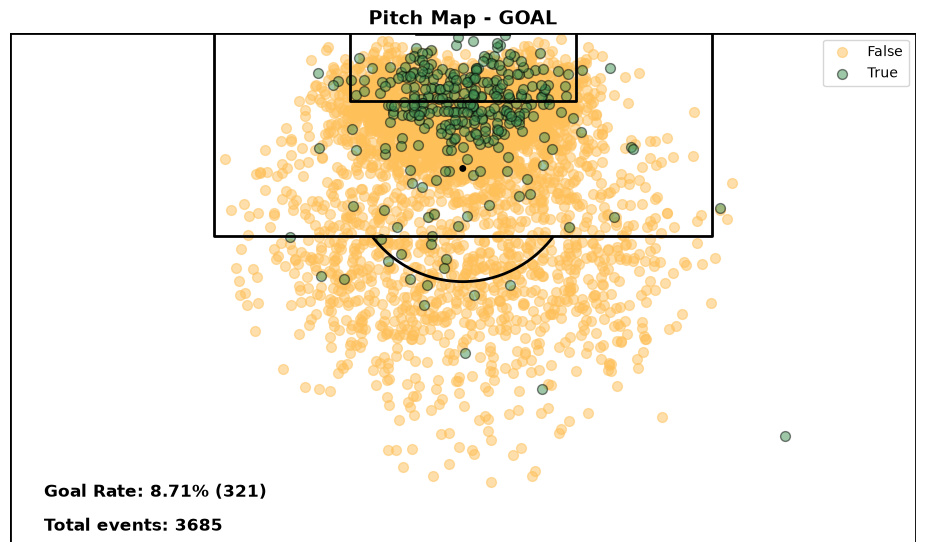

In [64]:
fig, ax = plot_pitch_map(data, target="goal", vertical_pitch=True, length_lim=(75, 120), colors=COLOR_MIX_YG)

The shot map shows that **goals are concentrated in central areas close to the goal**, while shots from further away and wider positions are much less likely to result in a goal. The spatial distribution suggests that **distance to goal** and **shot angle** are likely to be important features for the xG model.

### Feature Binning

In [65]:
def bin_shot_technique(shot_technique: str) -> str:
    if shot_technique in ["Normal", "Volley", "Half Volley"]:
        return shot_technique
    return "Other"


data["shot_technique"] = data["shot_technique"].apply(bin_shot_technique)

### One-Hot Encoding

Since the categorical variable have a group of fixed categories, the one-hot encoding can be applied before the data split/cross-validation. Otherwise, it would result in data leakage. 

In [66]:
ct = ColumnTransformer(
    [
        (
            'oneHot', 
            OneHotEncoder(
                drop='if_binary',
                sparse_output=False,
                handle_unknown='ignore',
                dtype=bool,
            ),
            categorical_cols
        )
    ],
    remainder="passthrough",
    verbose_feature_names_out=False,
).set_output(transform="pandas")

data = ct.fit_transform(data)
data

,shot_body_part_Head,shot_body_part_Left Foot,shot_body_part_Other,shot_body_part_Right Foot,shot_technique_Half Volley,shot_technique_Normal,shot_technique_Other,shot_technique_Volley,under_pressure,shot_first_time,...,nearest_teammate_2_distance,nearest_teammate_3_distance,teammates_within_1m,teammates_within_3m,teammates_within_5m,teammates_in_shot_triangle,x,y,z,goal
2964,True,False,False,False,False,True,False,False,False,False,...,5.538748,9.314861,0.0,0.0,1.0,0.0,110.8,32.8,2.00,True
6000,True,False,False,False,False,True,False,False,False,False,...,7.663953,8.614523,0.0,0.0,0.0,0.0,112.6,48.9,1.89,False
6001,True,False,False,False,False,True,False,False,True,False,...,5.581463,5.847842,0.0,1.0,1.0,0.0,112.0,39.0,2.17,True
6002,False,False,False,True,False,False,False,True,False,True,...,5.391364,11.246451,0.0,0.0,0.0,1.0,97.8,41.6,0.44,False
6005,True,False,False,False,False,True,False,False,False,False,...,9.826695,12.690616,0.0,0.0,1.0,0.0,117.5,34.0,1.94,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2994949,False,False,False,True,False,True,False,False,True,False,...,11.591760,12.093025,1.0,1.0,1.0,1.0,101.0,23.0,0.00,False
2994950,False,True,False,False,True,False,False,False,True,False,...,8.416463,9.904005,1.0,1.0,1.0,2.0,94.2,44.1,0.48,False
2994957,True,False,False,False,False,True,False,False,False,False,...,2.776482,3.343603,1.0,2.0,3.0,2.0,111.8,37.0,2.32,False
2997563,True,False,False,False,False,True,False,False,False,False,...,3.854822,6.894484,0.0,1.0,2.0,0.0,112.8,33.4,2.17,False


### Target Distinction

In [67]:
X = data.drop(columns=["goal"])
y = data["goal"]

### Data Splitting

In [68]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=21, stratify=y
)

## Modeling

**Methodology**

Model selection is framed as a strict two-stage process to avoid any leakage between tuning and evaluation. The raw dataset is split once into a development set and an untouched test set; every search, comparison, and feature-selection decision described below operates exclusively on the development portion, with the test set reserved for a single final evaluation pass per candidate model.

For each of the nine model families considered — three regularized logistic regressions, a decision tree, random forest, extra trees, gradient boosting, histogram-based gradient boosting, and XGBoost — a dedicated pipeline is constructed consisting of preprocessing, feature selection, and the classifier itself. Preprocessing is matched to what each estimator can natively tolerate: linear models receive median-imputed, indicator-augmented, and scaled numeric predictors, since they are sensitive to both missing values and feature scale; native tree-based estimators (decision tree, random forest, extra trees, histogram gradient boosting, XGBoost) receive predictors with missing values left intact, since these estimators route NaNs through learned split directions rather than requiring imputation; and `GradientBoostingClassifier`, which cannot handle NaNs natively but is otherwise scale-invariant, receives median-imputed but unscaled predictors.

Feature selection is not left to a single method. Instead, three wrapper-based procedures — RFECV, forward sequential selection, and backward sequential selection — each cast a vote on every predictor, using an estimator matched to the model family currently being tuned. A predictor is retained if at least two of the three procedures vote to keep it. Complete binary predictors are given a secondary path into the pipeline: if a binary feature receives exactly one vote (one below the retention threshold) but shows a statistically significant association with the target under a chi-square test (p < 0.05), it is rescued and retained anyway. This reflects the view that wrapper methods, which are sensitive to interactions and current model fit, can under-vote for binary variables whose marginal association with the outcome is nonetheless real and worth preserving.

Hyperparameters for each model are then tuned via Bayesian optimization (`BayesSearchCV`) over five-fold stratified cross-validation, scored on negative log loss. Because feature selection is embedded inside the pipeline rather than applied upfront, it is refit independently within each training fold, so the selected feature set — and therefore the selector's vote counts — can legitimately vary fold to fold; the vote counts and support mask reported at the end reflect only the final refit on the full development set, not an aggregate across folds. This keeps the reported cross-validated log loss honest: no information about which features "work well" on validation folds leaks into how those folds are constructed.

Once all requested models have been searched, their development-set cross-validated log losses are compared directly, and a single model family is chosen based on this comparison alone — before the test set is touched. Only after that choice is finalized are held-out predictions generated once, yielding log loss, Brier score, ROC AUC, average precision, and calibration diagnostics (mean predicted xG vs. actual goal rate) that serve as the final, leakage-free estimate of real-world performance.

In [69]:
models = [
    "logistic_elasticnet",
    "random_forest",
    "hist_gradient_boosting",
    "xgboost",
]

### Search

<!-- For binary classification—including predicting goal vs. no goal—the main models are:

**Tree-based models**

Single-tree model
- Decision Tree Classifier
- Bagging and randomized ensembles
- Random Forest Classifier
- Extra Trees Classifier
- Bagging Classifier with decision trees

Boosted-tree models
- Gradient Boosting Classifier
- Histogram-based Gradient Boosting Classifier
- XGBoost
- LightGBM
- CatBoost
- AdaBoost with decision-tree stumps

For xG, the strongest practical candidates are usually gradient-boosted trees, particularly XGBoost, LightGBM, CatBoost, and HistGradientBoosting.

<br>

**Linear models**

Probabilistic linear models
- Logistic Regression
- Logistic Regression with L1 regularization
- Logistic Regression with L2 regularization
- Elastic Net Logistic Regression
- Bayesian Logistic Regression
- Generalized Linear Model with binomial family and logit link

Other linear classifiers
- Linear Support Vector Classifier
- SGD Classifier
- logistic-loss version
- modified Huber or hinge-loss versions
- Perceptron
- Passive-Aggressive Classifier
- Linear Discriminant Analysis
- Quadratic Discriminant Analysis is related, but its decision boundary is nonlinear

For xG, I would prioritize the models that produce probabilities naturally:
- Standard/L2 logistic regression as the baseline
- Elastic Net logistic regression for selection and regularization
- A binomial generalized linear model when statistical inference is important

Linear SVM, Perceptron, and Passive-Aggressive models are generally less appropriate because their raw outputs are not probabilities. Probability calibration can be added, but there is usually little reason to prefer them over logistic regression for xG.

One terminology detail: XGBoost, LightGBM, and CatBoost are tree-based when configured with their standard tree boosters. XGBoost can also use a linear booster, so its model family depends on its configuration. -->

Use this cell if you have not download the data yet:

In [70]:
##### NOTE: This cell takes more than 4 hours to run #####
# results = fit_model_searches(
#     X_train,
#     y_train,
#     models=models,
#     n_iter=20,
#     bayes_cv_splits=5,
#     selector_cv_splits=3,
#     min_votes=2,
#     n_jobs=-1,
#     verbose=1,
#     cache_dir=".model_selection_cache",
# )

In [ ]:
# checkpoint_path = save_model_checkpoint(
#     results,
#     "temp/model_search_checkpoint.pkl.gz",
#     X_test=X_test,
#     y_test=y_test,
# )

# verify_model_checkpoint(
#     results,
#     checkpoint_path,
#     X_test,
# )

Use this cell if you have already download the data:

In [ ]:
import utils.modeling
from utils.modeling.search import ModelSearchResult, VotingFeatureSelector

utils.modeling.ModelSearchResult = ModelSearchResult
utils.modeling.VotingFeatureSelector = VotingFeatureSelector


checkpoint = load_model_checkpoint(
    "temp/model_search_checkpoint.pkl.gz"
)
results = checkpoint["results"]


Checkpoint loaded: C:\Users\PC\Documents\Sports Data Campus\Big Data Master\PFM\data\temp\xg_model_search_checkpoint.pkl.gz
Models available: ['logistic_elasticnet', 'random_forest', 'hist_gradient_boosting', 'xgboost']


#### Comparison

In [73]:
compare_searches(results)

,model,cv_log_loss,n_selected_features,selected_features,best_parameters
0,hist_gradient_boosting,0.254478,15,"[shot_technique_Half Volley, shot_technique_Ot...","{'model__l2_regularization': 20.0, 'model__lea..."
1,random_forest,0.255397,27,"[shot_body_part_Head, shot_body_part_Left Foot...","{'model__criterion': 'log_loss', 'model__max_d..."
2,xgboost,0.255651,21,"[shot_technique_Half Volley, shot_technique_No...",{'model__colsample_bytree': 0.9882925016105311...
3,logistic_elasticnet,0.257724,23,"[shot_technique_Half Volley, shot_technique_Ot...","{'model__C': 0.07525469500337494, 'model__l1_r..."


### Model Evaluation

Statsbomb xG model is being used as a baseline for the evaluation. Since the Statsbomb model accounts for all types of shots, using it in this evaluation helps us determine whether creating a model specifically for set pieces is useful. However, one must remember that the number of observations available for this analysis is quite small.

In [74]:
statsbomb_train_xg = xg_baseline.loc[X_train.index].astype(float)
statsbomb_test_xg = xg_baseline.loc[X_test.index].astype(float)

In [75]:
statsbomb_train_results = evaluate_probabilities(y_train, statsbomb_train_xg.to_numpy())
statsbomb_test_results = evaluate_probabilities(y_test, statsbomb_test_xg.to_numpy())

In [76]:
test_predictions = {
    model_name: results[
        model_name
    ].estimator.predict_proba(X_test)[:, 1]
    for model_name in models
}
test_predictions["statsbomb"] = statsbomb_test_xg.to_numpy()

#### Search Results

In [77]:
train_model_results = evaluate_searches(results, X_train, y_train, models=models)
train_model_results.loc["statsbomb"] = statsbomb_train_results
train_model_results

,log_loss,brier_score,roc_auc,average_precision,mean_xg,actual_goal_rate,expected_goals,actual_goals
xgboost,0.223882,0.062905,0.851439,0.450687,0.087326,0.087178,257.437803,257.0
random_forest,0.237540,0.066117,0.816548,0.399034,0.087128,0.087178,256.854404,257.0
hist_gradient_boosting,0.238199,0.066367,0.811789,0.376966,0.087161,0.087178,256.950952,257.0
logistic_elasticnet,0.249111,0.068976,0.779801,0.335407,0.087183,0.087178,257.015563,257.0
statsbomb,0.248597,0.068197,0.776085,0.353064,0.092402,0.087178,272.400264,257.0


In [78]:
test_model_results = evaluate_searches(results, X_test, y_test, models=models)
test_model_results.loc["statsbomb"] = statsbomb_test_results
test_model_results

,log_loss,brier_score,roc_auc,average_precision,mean_xg,actual_goal_rate,expected_goals,actual_goals
hist_gradient_boosting,0.254819,0.069731,0.747365,0.311920,0.082480,0.086839,60.787750,64.0
xgboost,0.255691,0.069888,0.746448,0.307269,0.083236,0.086839,61.344961,64.0
random_forest,0.256323,0.070138,0.741526,0.303694,0.082656,0.086839,60.917714,64.0
logistic_elasticnet,0.259354,0.071075,0.733934,0.298232,0.083591,0.086839,61.606464,64.0
statsbomb,0.257461,0.069721,0.742060,0.316505,0.085510,0.086839,63.020848,64.0


All internally trained models perform better on the training data than on the test data, indicating some degree of overfitting. This comparison must be interpreted cautiously because the training predictions are in-sample predictions from data used for preprocessing, feature selection, hyperparameter optimization, and final fitting.

**StatsBomb** is treated as an external benchmark. Its train–test difference cannot be interpreted as overfitting in the same way because the **StatsBomb** model was not fitted on this project’s training partition.

| Model                    | Train log loss | Test log loss |  Train AUC |   Test AUC |
| ------------------------ | -------------: | ------------: | ---------: | ---------: |
| **XGBoost**              |     **0.2239** |        0.2557 | **0.8514** |     0.7464 |
| **Random Forest**        |         0.2375 |        0.2563 |     0.8165 |     0.7415 |
| **HistGradientBoosting** |         0.2382 |    **0.2548** |     0.8118 | **0.7474** |
| **Elastic-Net logistic** |         0.2491 |        0.2594 |     0.7798 |     0.7339 |
| **StatsBomb**            |         0.2486 |        0.2575 |     0.7761 |     0.7421 |

**XGBoost** achieves the strongest training performance but experiences the largest deterioration on the test set. Its ROC-AUC falls from `0.851` to `0.746`, while its average precision falls from `0.451` to `0.307`. This is the clearest indication of overfitting among the internally trained models.

**Random Forest** also shows noticeable overfitting. **HistGradientBoosting** has a smaller train–test gap and produces the best test log loss and ROC-AUC. It therefore provides the best balance between predictive performance and generalization among the internally developed models.

**Elastic-Net logistic** regression has the smallest train–test gap among the internally trained models, as expected from a simpler regularized model, but its test performance is weaker than that of the tree-based alternatives.

**StatsBomb** is highly competitive on the test set. It obtains the lowest Brier score, the highest average precision, and the closest aggregate goal estimate: `63.02` expected goals compared with `64` observed. **HistGradientBoosting** underestimates the total more noticeably, predicting `60.79` expected goals.

No model dominates every evaluation dimension. **HistGradientBoosting** produces the best test log loss and ROC-AUC, whereas **StatsBomb** produces the best Brier score, average precision, and overall goal estimate. The differences are very small, so a paired bootstrap comparison between **HistGradientBoosting** and **StatsBomb** is required before concluding that either model is superior.

Overall, **HistGradientBoosting** remains the preferred internally developed model, while **StatsBomb** provides a strong external benchmark with essentially equivalent test performance. Therefore, the current results show that constructing a set-piece-specific xG model is viable and competitive, but they do not yet demonstrate a clear overall improvement.

#### Bootstrapping

In [79]:
bootstrap_estimates, bootstrap_comparisons = (
    paired_bootstrap(
        y_test,
        test_predictions,
        reference_model="hist_gradient_boosting",
        n_bootstrap=5000,
        random_state=21,
    )
)

In [80]:
bootstrap_estimates

,model,metric,estimate,ci_lower,ci_upper,bootstrap_std
0,logistic_elasticnet,log_loss,0.259354,0.237299,0.280592,0.011006
1,logistic_elasticnet,brier_score,0.071075,0.065110,0.076453,0.002922
2,logistic_elasticnet,roc_auc,0.733934,0.659149,0.804380,0.036569
3,logistic_elasticnet,average_precision,0.298232,0.215390,0.421461,0.053178
4,random_forest,log_loss,0.256323,0.234872,0.277210,0.010904
5,random_forest,brier_score,0.070138,0.064346,0.075452,0.002872
6,random_forest,roc_auc,0.741526,0.669687,0.810898,0.036435
7,random_forest,average_precision,0.303694,0.220453,0.434586,0.054758
8,hist_gradient_boosting,log_loss,0.254819,0.232909,0.276523,0.011073
9,hist_gradient_boosting,brier_score,0.069731,0.063748,0.075283,0.002908


**HistGradientBoosting** remains the preferred internally developed model based on the bootstrap point estimates. It produces the lowest log loss and highest ROC-AUC. However, **StatsBomb** obtains the lowest Brier score and highest average precision.

The differences are very small relative to the bootstrap uncertainty. The confidence intervals are wide and overlap substantially across all models. In particular, **HistGradientBoosting**, **XGBoost**, and **StatsBomb** show similar probability quality and discrimination, with no model clearly dominating every metric.

These results indicate that the set-piece-specific model is competitive with **StatsBomb** but do not yet demonstrate a clear overall improvement. **HistGradientBoosting** appears slightly stronger in log loss and ranking performance, whereas **StatsBomb** appears slightly stronger in squared probability error and identifying goals.

In [81]:
bootstrap_comparisons[bootstrap_comparisons["model"] == "xgboost"]

,model,reference,metric,difference,ci_lower,ci_upper,includes_zero
8,xgboost,hist_gradient_boosting,log_loss,0.000871,-0.003905,0.005634,True
9,xgboost,hist_gradient_boosting,brier_score,0.000158,-0.001359,0.001662,True
10,xgboost,hist_gradient_boosting,roc_auc,-0.000917,-0.016148,0.014419,True
11,xgboost,hist_gradient_boosting,average_precision,-0.004651,-0.034810,0.034996,True


The paired bootstrap comparison finds no statistically distinguishable difference between **HistGradientBoosting** and **XGBoost**. Every 95% confidence interval includes zero:

| Metric            | **XGBoost** − **HistGradientBoosting** | 95% confidence interval |
| ----------------- | -----------------------------: | ----------------------: |
| Log loss          |                      +0.000871 |   [−0.003905, 0.005634] |
| Brier score       |                      +0.000158 |   [−0.001359, 0.001662] |
| ROC-AUC           |                      −0.000917 |   [−0.016148, 0.014419] |
| Average precision |                      −0.004651 |   [−0.034810, 0.034996] |

The point estimates favor **HistGradientBoosting** slightly: it has lower log loss and Brier score and higher ROC-AUC and average precision. However, the differences are very small relative to their uncertainty and could plausibly favor either model in another sample.

Consequently, **HistGradientBoosting** and **XGBoost** should be considered equivalent in predictive performance on the available test data. The final choice should therefore be based on calibration, resistance to overfitting, inference speed, and maintainability. **HistGradientBoosting** currently has a modest practical advantage because it showed a smaller train–test performance gap while achieving the best test-set point estimates.

In [82]:
bootstrap_comparisons[bootstrap_comparisons["model"] == "statsbomb"]

,model,reference,metric,difference,ci_lower,ci_upper,includes_zero
12,statsbomb,hist_gradient_boosting,log_loss,0.002641,-0.008888,0.014888,True
13,statsbomb,hist_gradient_boosting,brier_score,-0.000010,-0.003634,0.003640,True
14,statsbomb,hist_gradient_boosting,roc_auc,-0.005305,-0.036950,0.023543,True
15,statsbomb,hist_gradient_boosting,average_precision,0.004585,-0.059496,0.073809,True


The paired bootstrap comparison finds no statistically distinguishable difference between **HistGradientBoosting** and **StatsBomb**. Every 95% confidence interval includes zero.

| Metric            | StatsBomb − HistGradientBoosting | 95% confidence interval |
| ----------------- | -------------------------------: | ----------------------: |
| Log loss          |                        +0.002641 |   [−0.008888, 0.014888] |
| Brier score       |                        −0.000010 |   [−0.003634, 0.003640] |
| ROC-AUC           |                        −0.005305 |   [−0.036950, 0.023543] |
| Average precision |                        +0.004585 |   [−0.059496, 0.073809] |

The point estimates slightly favor **HistGradientBoosting** in log loss and ROC-AUC, while **StatsBomb** is marginally better in Brier score and average precision. However, these differences are negligible relative to their uncertainty and could plausibly favor either model in another sample.

Consequently, the specialized set-piece model matches **StatsBomb**’s overall predictive performance but does not demonstrate a statistically significant improvement. This establishes that developing a dedicated set-piece xG model is viable, although the current evidence does not show that specialization improves aggregate prediction quality.

#### Calibration

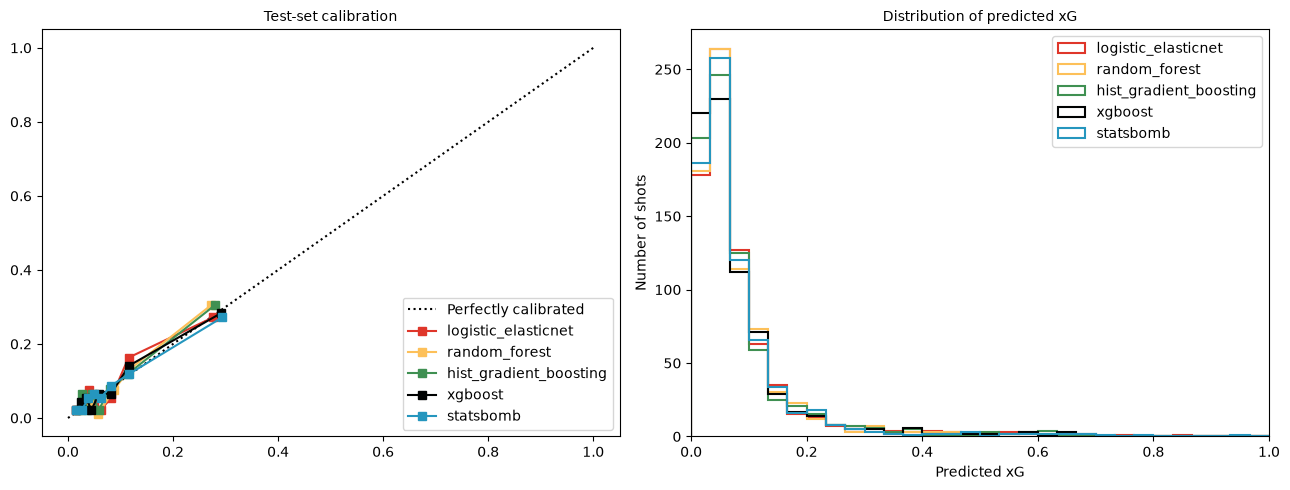

In [83]:
n_models = len(test_predictions)
sampled_colors = custom_cmap_rygbb(np.linspace(0, 1, n_models))
colors = dict(zip(test_predictions.keys(), sampled_colors))

fig, (ax1, ax2) = plot_calibration_and_distribution(y_test, test_predictions, colors=colors)

The calibration curves are generally close to the perfect-calibration diagonal, indicating that the internally developed models and **StatsBomb** produce reasonably reliable probabilities for the set-piece shots in the test set. Differences are small, and no model is a clear visual winner.

In the highest-probability group, **HistGradientBoosting** and **Random Forest** appear to slightly underestimate the observed scoring rate, whereas **StatsBomb** slightly overestimates it. **XGBoost** and **Elastic Net** are positioned between these behaviours. Deviations in the lowest-probability groups should be interpreted cautiously because relatively few goals occur in each bin.

The predicted-xG distributions are also very similar. Most shots receive probabilities below approximately `0.15`, while a small number of high-quality chances form a long right tail. **StatsBomb** follows broadly the same distribution as the specialized models, suggesting that their main differences concern the probabilities assigned to individual shots rather than the overall range of predictions.

Overall, the plot provides no clear visual evidence that the set-piece-specific models are better calibrated than **StatsBomb**. However, it also shows that the specialized models achieve comparable calibration while using features designed to represent set-piece-specific context. Combined with the paired bootstrap results, **HistGradientBoosting** and **StatsBomb** should be considered broadly equivalent at the aggregate level.

In [84]:
calibration_results = calibration_statistics(
    y_test,
    test_predictions,
    n_bins=8,
)

calibration_results

,calibration_intercept,calibration_slope,ece,mean_xg,actual_goal_rate
model,,,,,
statsbomb,-0.191480,0.898983,0.010128,0.085510,0.086839
xgboost,-0.080718,0.935554,0.015429,0.083236,0.086839
hist_gradient_boosting,0.064499,1.000472,0.018148,0.082480,0.086839
random_forest,0.051095,0.995458,0.018695,0.082656,0.086839
logistic_elasticnet,-0.078287,0.940714,0.023012,0.083591,0.086839


**HistGradientBoosting** presents the strongest calibration structure among the internally developed models. Its calibration slope is almost exactly ideal, indicating that its probabilities are neither excessively extreme nor overly compressed. Its intercept is also reasonably close to zero.

**Random Forest** produces similarly good calibration, with a slope of `0.9955` and an intercept of `0.0511`, although it previously showed slightly weaker predictive performance than **HistGradientBoosting**.

**StatsBomb** has the lowest expected calibration error and the mean predicted xG closest to the observed goal rate. It predicts an average probability of `0.0855`, compared with an actual scoring rate of `0.0868`. However, its calibration slope of `0.8990` indicates that its probabilities are somewhat too extreme, while its intercept is farther from zero than those of the internally developed models. Because the intercept and slope were estimated jointly, they must be interpreted together.

**XGBoost** has the second-lowest ECE, but its slope of `0.9356` also suggests moderately excessive probability variation. This is consistent with its larger train–test performance gap. **Elastic Net** shows similar behaviour and has the highest ECE, making it the weakest internally developed model according to these calibration measures.

All models slightly underestimate the overall scoring rate. The difference is smallest for **StatsBomb** at approximately `0.13` percentage points, while the internally developed models underestimate it by approximately `0.32–0.44` percentage points.

No model dominates every calibration measure. **StatsBomb** performs best in terms of binned calibration error and aggregate scoring rate, whereas **HistGradientBoosting** has the most appropriate probability spread, reflected by its almost perfect calibration slope. Since ECE depends on the chosen bins, its small numerical advantage should not be considered decisive.

Overall, **HistGradientBoosting** remains the strongest internally developed model and demonstrates that a set-piece-specific model can achieve a well-calibrated probability structure. However, it does not show a clear overall calibration improvement over **StatsBomb**: each performs better on different calibration dimensions, and their paired predictive differences are statistically indistinguishable.


#### Inference Time

In [85]:
inference_speed = benchmark_inference(
    results,
    X_test,
    models=models,
    n_repeats=100,
)

inference_speed

,median_seconds,mean_seconds,std_seconds,shots_per_second
model,,,,
logistic_elasticnet,0.008341,0.008943,0.001843,88356.061743
xgboost,0.008740,0.009151,0.002160,84323.013200
random_forest,0.031829,0.033431,0.005370,23155.129946
hist_gradient_boosting,0.042534,0.042755,0.003719,17327.355357


**Elastic-Net logistic regression** is the fastest model, processing approximately 131,000 shots per second. **XGBoost** follows closely at around 98,000 shots per second, while **Random Forest** and **HistGradientBoosting** process approximately 32,000 and 24,000 shots per second, respectively.

**HistGradientBoosting** is the slowest model, requiring a median of approximately `0.031` seconds to predict the complete test set. It is roughly four times slower than **XGBoost** and five times slower than **Elastic Net**. However, the absolute prediction time remains extremely small: approximately 31 milliseconds for 737 shots.

Consequently, inference speed is unlikely to be an important practical constraint for this project. Even the slowest model can process thousands of shots almost instantaneously. The observed variability is also small, although **HistGradientBoosting** has the highest timing variation.

**XGBoost** offers the strongest speed among the nonlinear models, but **HistGradientBoosting**’s slower inference does not outweigh its advantages in calibration, generalization, and test-set performance. **HistGradientBoosting** therefore remains the preferred model unless the application requires very high-frequency or real-time prediction at substantially larger scale.


#### Conclusion

**HistGradientBoosting** is the best internally developed model. It provides the strongest balance between predictive performance, calibration, and resistance to overfitting. It achieves the lowest test log loss, the highest ROC-AUC, and an almost ideal calibration slope.

| Metric            | **HistGradientBoosting** |    **StatsBomb** | Best point estimate   |
| ----------------- | -------------------: | -----------: | --------------------- |
| Log loss          |         **0.254819** |     0.257461 | **HistGradientBoosting**  |
| Brier score       |             0.069731 | **0.069721** | Effectively identical |
| ROC-AUC           |         **0.747365** |     0.742060 | **HistGradientBoosting**  |
| Average precision |             0.311920 | **0.316505** | **StatsBomb**             |

Compared with **StatsBomb**, **HistGradientBoosting** reduces log loss by approximately 1% and improves ROC-AUC by `0.0053`. **StatsBomb** achieves a marginally lower Brier score and higher average precision. Consequently, neither model dominates every evaluation dimension.

The paired bootstrap comparison shows that the confidence intervals for all metric differences include zero. The observed advantages may therefore be caused by sampling variation, and there is no statistically significant evidence that either model is superior.

The calibration analysis produces a similarly balanced result. **HistGradientBoosting** has an almost perfect calibration slope, suggesting an appropriate spread of predicted probabilities. **StatsBomb** has a lower expected calibration error and predicts the aggregate scoring rate more accurately. Thus, each model performs better on different aspects of calibration.

Dataset size is an important limitation. The specialized model was developed with fewer than 4,000 observations, while **StatsBomb** benefits from a training base of millions of shots. The test set contains only 737 shots and 64 goals, resulting in relatively wide confidence intervals and limited statistical power to detect small performance differences.

Despite this limitation, the specialized model achieves performance comparable to **StatsBomb**. This suggests that detailed set-piece-specific information—such as goalkeeper positioning, defensive obstruction, and nearby-player locations—may compensate partially for the much smaller training sample.

Overall, the results support **competitive equivalence rather than superiority**. **HistGradientBoosting** is the preferred model for continuing the development of a specialized set-piece xG framework, but the current evidence does not demonstrate a clear overall improvement over **StatsBomb**. A larger dataset and validation on independent seasons or competitions would be required to establish whether the observed point-estimate improvements represent a genuine advantage.


In [86]:
best_result = results["hist_gradient_boosting"]

In [87]:
best_pipeline = best_result.estimator
best_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('selector', ...), ...]"
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",'.model_selection_cache'
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[bool](2,)","[False, True]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](46,)","['shot_body_part_Head','shot_body_part_Left Foot','shot_body_part_Other', ...,'x','y','z']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,46
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('boolean', ...), ('numeric', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transform

In [88]:
best_model = best_pipeline.named_steps["model"]
best_model

,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.01
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees for binary classification. For multiclassclassification, `n_classes` trees per iteration are built.",700
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",7
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",2
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",40
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",20.0
,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",21
,"loss loss: {'log_loss'}, default='log_loss'The loss function to use in the boosting process.For binary classification problems, 'log_loss' is also known as logistic loss,binomial deviance or binary crossentropy. Internally, the model fits one treeper boosting iteration and uses the logistic sigmoid function (expit) asinverse link function to compute the predicted positive class probability.For multiclass classification problems, 'log_loss' is also known as multinomialdeviance or categorical crossentropy. Internally, the model fits one tree perboosting iteration and per class and uses the softmax function as inverse linkfunction to compute the predicted probabilities of the classes.",'log_loss'
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255
,"categorical_features categorical_features: array-like of {bool, int, str} of shape (n_features) or shape (n_categorical_features,), default='from_dtype'Indicates the categorical features.- None : no feature will be considered categorical.- boolean array-like : boolean mask indicating categorical features.- integer array-like : integer indices indicating categorical features.- str array-like: names of categorical features (assuming the training data has feature names).- `""from_dtype""`: dataframe columns with dtype ""Categorical"" and ""Enum"" are considered to be categorical features. The input must be a dataframe that is supported by narwhals (or supports it): :func:`narwhals.from_native` must work. This is the case, for instance, for pandas and polars DataFrames.For each categorical feature, there must be at most `max_bins` uniquecategories. Negative values for categorical features encoded as numericdtypes are treated as missing value

In [89]:
best_parameters = best_model.get_params()
best_parameters

{'categorical_features': 'from_dtype',
 'class_weight': None,
 'early_stopping': 'auto',
 'interaction_cst': None,
 'l2_regularization': 20.0,
 'learning_rate': 0.01,
 'loss': 'log_loss',
 'max_bins': 255,
 'max_depth': 2,
 'max_features': 1.0,
 'max_iter': 700,
 'max_leaf_nodes': 7,
 'min_samples_leaf': 40,
 'monotonic_cst': None,
 'n_iter_no_change': 10,
 'random_state': 21,
 'scoring': 'loss',
 'tol': 1e-07,
 'validation_fraction': 0.1,
 'verbose': 0,
 'warm_start': False}

In [90]:
selected_features = best_result.selected_features

print(f"Number of selected features: {len(selected_features)}")

for feature in selected_features:
    print(feature)

Number of selected features: 15
shot_technique_Half Volley
shot_technique_Other
shot_first_time
shot_one_on_one
shot_open_goal
shot_aerial_won
shot_assisted
shot_distance_to_goal
shot_distance_to_goal_center
nearest_defender_2_distance
defenders_within_3m
defenders_within_5m
open_goal_angle
gk_distance_to_ball
gk_goal_angle_coverage


### Define Model

In [91]:
preprocessor = clone(best_pipeline.named_steps["preprocessor"])
model = clone(best_pipeline.named_steps["model"])

# Define a new ColumnTransformer that only includes the selected features
# In order to avoid running the feature selection step again
fixed_selector = ColumnTransformer(
    transformers=[
        (
            "selected",
            "passthrough",
            selected_features,
        ),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
).set_output(transform="pandas")

final_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("selector", fixed_selector),
        ("model", model),
    ]
)
final_pipeline.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('selector', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[bool](2,)","[False, True]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](46,)","['shot_body_part_Head','shot_body_part_Left Foot','shot_body_part_Other', ...,'x','y','z']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,46
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('boolean', ...), ('numeric', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated th

Uncomment the following line to save the final pipeline to a joblib file:

In [ ]:
# joblib.dump(final_pipeline, "models/pipeline.joblib")

['models/set_piece_xg_pipeline.joblib']

### Assign Set-Piece xG to Event Data

In [93]:
final_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=21,
)

shot_set_piece_xg = cross_val_predict(
    estimator=clone(final_pipeline),
    X=X,
    y=y,
    cv=final_cv,
    method="predict_proba",
    n_jobs=-1,
)[:, 1]
shot_set_piece_xg = pd.Series(
    shot_set_piece_xg,
    index=X.index,
    name="shot_set_piece_xg",
)

events["shot_set_piece_xg"] = np.nan
events.loc[
    shot_set_piece_xg.index,
    "shot_set_piece_xg",
] = shot_set_piece_xg
events.to_csv("data/events_with_set_piece_xg.csv", index=False)

## Feature Importance

In [94]:
explainer = shap.TreeExplainer(model)
shap_values = explainer(X[selected_features])

### Check Additivity 

In [95]:
check_shap_additivity(
    shap_values, model, X[selected_features], 
    selected_features=selected_features, verbose=False
)

np.float64(7.105427357601002e-15)

This check verifies the **additivity property** of SHAP values: for every prediction, the base value plus the sum of all feature contributions should exactly reconstruct the model's raw output.

$$
\text{base\_value} + \sum_{i} \phi_i = f(x)
$$

A maximum error on the order of `1e-15`–`1e-14` is expected and reflects standard floating-point rounding, **not** a real discrepancy. This confirms the SHAP values fully and correctly attribute the prediction to the input features, with nothing missing or double-counted.

A large error (e.g. > 1e-3) would instead indicate a problem such as:
- Mismatched feature ordering between `X` and `shap_values`
- A `link` function mismatch (e.g. comparing against `predict_proba` instead of `decision_function`)
- An approximate explainer configuration that breaks exact additivity

In [96]:
check_shap_additivity_proba(
    shap_values, model, X[selected_features], 
    selected_features=selected_features, verbose=False
)

np.float64(1.7208456881689926e-15)

This check confirms additivity holds after mapping the raw model output through the **sigmoid (logistic) link function**, `expit`, into probability space:

$$
\text{expit}\left(\text{base\_value} + \sum_{i} \phi_i\right) \approx P(y=1 \mid x)
$$

This is a stronger, more practically relevant check than the raw-output version, since it verifies that reconstructing SHAP values through the link function matches `predict_proba` — the quantity most people actually interpret and report.

A max error on the order of `1e-15`–`1e-8` is expected numerical noise and confirms the SHAP explanation is consistent with the model's probability output.

A larger error would suggest a **link function mismatch** — for example, if the SHAP explainer was configured with `link="identity"` instead of `link="logit"`, additivity would hold in raw-output (logit) space but only approximately, or not at all, after applying `expit`.

### Ranking

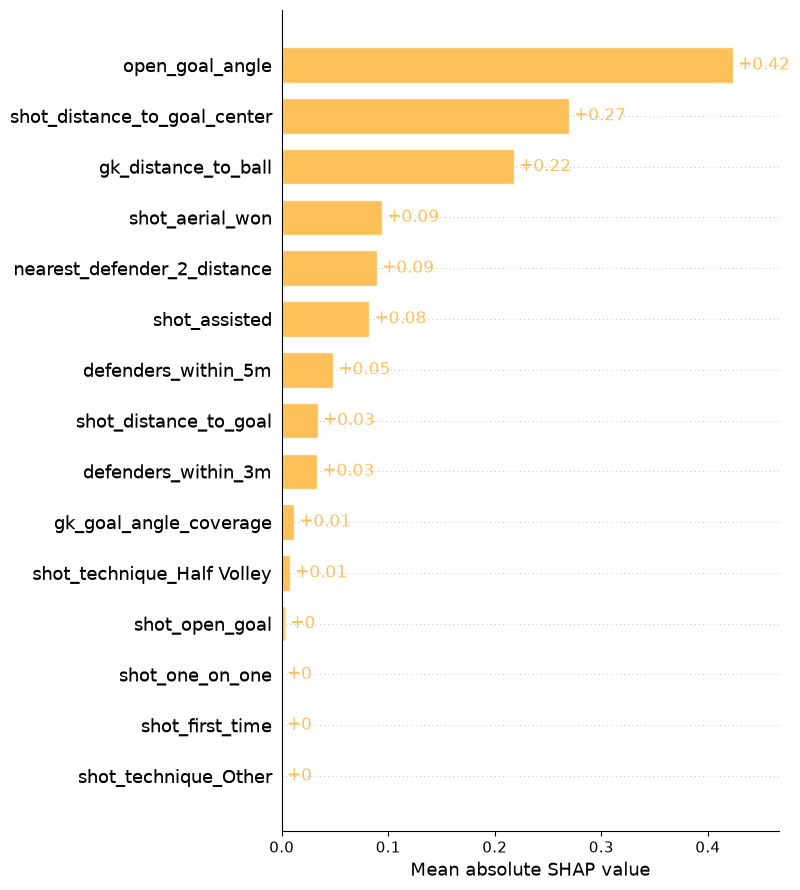

In [97]:
plot_shap_bar(shap_values, color=COLOR_Y)

The bar plot summarises the SHAP values by reducing each feature to a single quantity: the mean absolute SHAP value across all observations. This provides an unsigned ranking of overall influence on predicted xG, without indicating whether a feature's effect is generally positive or negative. As before, these values are expressed on the model's raw output scale, approximately log-odds, rather than as direct percentage-point changes in xG.

`open_goal_angle` is by far the most influential variable, with a mean absolute contribution roughly 1.5 times larger than the second-ranked feature. This confirms that shot geometry dominates the model's predictions for set-piece situations. `shot_distance_to_goal_center` and `gk_distance_to_ball` follow as the second and third most important variables, reinforcing that proximity to goal and goalkeeper positioning are the primary drivers of shot quality alongside goal angle.

A second tier of features, `shot_aerial_won`, `nearest_defender_2_distance`, and `shot_assisted`, contribute noticeably less than the top three, though still at a non-trivial level. These represent secondary contextual and defensive-pressure effects rather than core geometric determinants.

Finally, feature selection and final-model importance are different concepts. The voting selector determines which variables are made available to HistGradientBoosting, but the final model may use some selected variables very little. This explains why `shot_one_on_one`, `shot_first_time`, and `shot_technique_Other` remain selected despite having SHAP values close to zero.

Overall, the bar plot establishes the relative magnitude of each feature's influence on the model's predictions.

### Summary

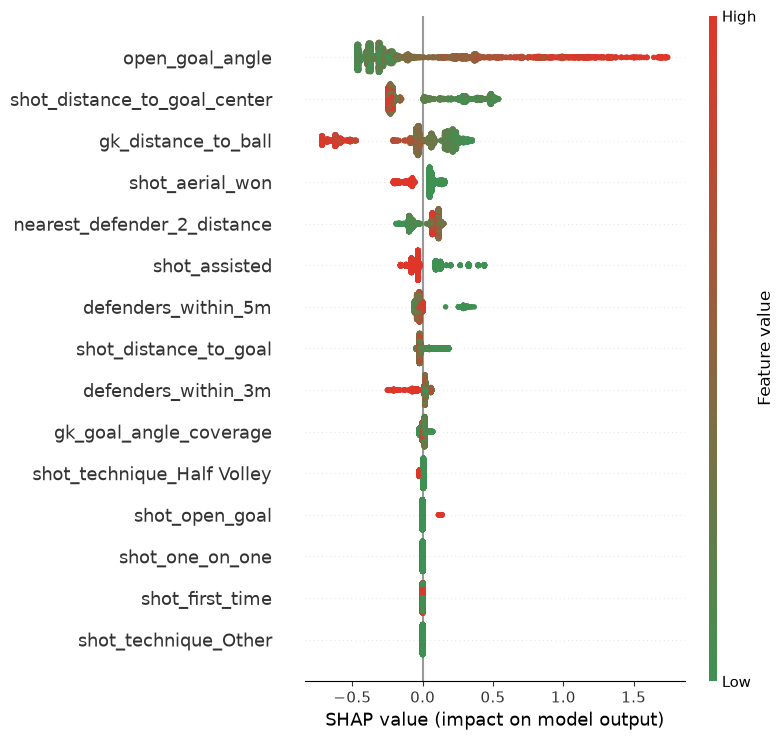

In [98]:
shap.summary_plot(shap_values, X[selected_features], cmap=custom_cmap_gr)

Because the SHAP values appear to have been calculated using the default `TreeExplainer` output, their scale likely represents the model’s raw output, approximately log-odds, rather than direct percentage-point changes in xG.

- `open_goal_angle`

This is clearly the most influential variable. Large open-goal angles strongly increase predicted xG, while small angles reduce it. The nonlinear positive tail indicates that exceptionally open views of the goal produce particularly large increases in shot quality.

- `shot_distance_to_goal_center`

Short distances to the centre of the goal increase predicted xG, whereas long distances reduce it. The strong separation between low and high values confirms that proximity to goal is one of the main determinants of set-piece shot quality.

- `gk_distance_to_ball`

Large goalkeeper-to-ball distances generally reduce predicted xG, while small distances increase it. Although this may initially appear counterintuitive, the variable is correlated with shot distance: when a shot is taken from far away, the goalkeeper remains close to the goal and is consequently far from the ball. Its SHAP contribution should therefore be interpreted jointly with the shot-distance variables rather than as an isolated causal effect.

- `shot_aerial_won`

Shots associated with a won aerial duel generally receive a negative contribution. This may identify headers or contested aerial situations in which the shooter has less control and faces greater defensive pressure. It does not imply that winning an aerial duel directly causes lower xG.

- `nearest_defender_2_distance`

A greater distance to the second-nearest defender generally increases predicted xG, while a shorter distance reduces it. This suggests that the presence of multiple nearby defenders is relevant: even if the closest defender is not ideally positioned, a second defender can still pressure the shooter or obstruct the shot.

- `shot_assisted`

Assisted shots generally receive a negative contribution, while some unassisted shots receive positive contributions. Within set pieces, assisted attempts may frequently be headers or shots following deliveries into crowded areas. Unassisted attempts may include rebounds, or loose balls situations. This result should therefore be interpreted as a contextual association rather than evidence that assistance itself reduces shot quality.

- `defenders_within_5m`

Having fewer defenders within five metres increases predicted xG, while greater defensive density generally reduces it. This variable represents the broader amount of defensive pressure surrounding the shooter.

- `shot_distance_to_goal`

Short shots increase predicted xG and long shots reduce it, as expected. Its importance is lower than that of `shot_distance_to_goal_center`, probably because both variables contain overlapping information. SHAP distributes attribution among correlated predictors, so the two distance variables should be interpreted as one broader shot-distance component.

- `defenders_within_3m`

More defenders within three metres clearly reduce predicted xG. This represents immediate pressure on the shooter and is more consistently negative than the wider five-metre count. The two defender-count variables are nested and correlated, so their effects should also be interpreted jointly.

- `gk_goal_angle_coverage`

Greater goalkeeper coverage of the available goal angle tends to reduce predicted xG, while low coverage can increase it slightly. This is football-intuitive: greater coverage leaves less exposed goal area. Its relatively small contribution suggests that some of the same information is already captured by `open_goal_angle` and `gk_distance_to_ball`.

- `shot_technique_Half Volley`

Half volleys have only a small negative effect on predicted xG. Most observations remain close to zero, indicating that this feature rarely changes the prediction substantially.

- `shot_open_goal`

Open-goal shots increase predicted xG, while non-open-goal shots have almost no contribution from this variable. The effect is smaller than might be expected because open goals are rare and their advantage is already represented by goal angle and goalkeeper-position variables.

- `shot_one_on_one`

This variable has almost no visible influence on the final predictions. Its information may overlap with goalkeeper positioning, open-goal angle, and shot distance, or there may be relatively few one-on-one observations in the dataset.

- `shot_first_time`

First-time shots produce only very small positive or negative changes. The model may use this feature in occasional interactions, but it does not materially affect most predictions.

- `shot_technique_Other`

This is the least influential selected feature. Its SHAP values are effectively zero, indicating that the final HistGradientBoosting model obtains almost no predictive contribution from it.

- Overall interpretation

The model is primarily driven by four groups of information:

1. **Shot geometry:** open-goal angle and distance to goal.
2. **Goalkeeper positioning:** goalkeeper-to-ball distance and goal-angle coverage.
3. **Defensive pressure:** nearby-defender distances and defender counts.
4. **Shot context:** aerial situations, assistance, and open goals.

The strongest relationships are football-intuitive: wider goal angles, shorter distances, fewer nearby defenders, and reduced goalkeeper coverage generally increase predicted xG.

Some apparently counterintuitive relationships—particularly those involving goalkeeper distance, assisted shots, and aerial duels—are likely produced by correlations and interactions specific to set-piece situations. SHAP explains how the fitted model distributes its predictions; it does not establish causal effects.

### Dependence

#### `open_goal_angle`

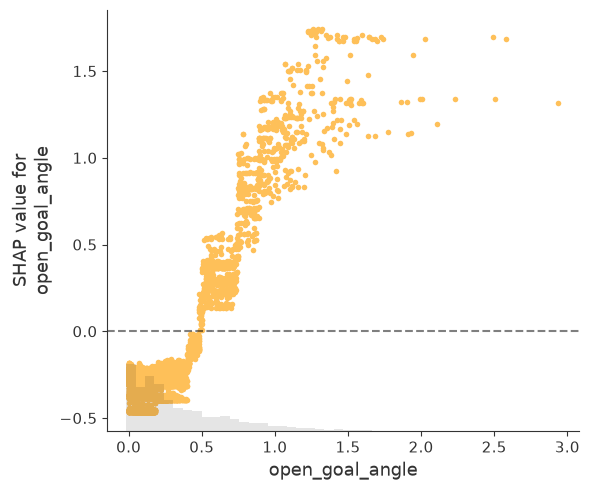

In [99]:
plot_shap_scatter(shap_values, feature="open_goal_angle", color=COLOR_Y)

The relationship is clearly nonlinear. For angles below approximately 0.4–0.5, the SHAP contribution is consistently negative, sitting around −0.2 to −0.5, with little variation. This indicates that narrow open-goal angles reliably suppress predicted xG, regardless of exactly how narrow the angle is.

Around an angle of 0.5, the SHAP value crosses zero and begins rising sharply. Between roughly 0.5 and 1.2, the contribution increases steeply and with considerable spread, suggesting this is the region where small changes in angle produce the largest changes in predicted xG, and where other features likely interact with `open_goal_angle` to produce the observed variation at a given angle.

Beyond an angle of approximately 1.2–1.5, the SHAP values plateau at high positive values, roughly 1.0 to 1.7, with increasingly sparse observations. This flattening indicates diminishing returns: once the goal angle is already very open, further widening it contributes comparatively little additional increase to predicted xG.

The grey histogram along the bottom shows the distribution of `open_goal_angle` itself, confirming that the vast majority of shots occur at low angles, while wide open-goal angles are comparatively rare. This should be kept in mind when interpreting the plateau region, as it is supported by fewer observations.

Overall, this dependence plot confirms `open_goal_angle` as a strong, monotonically increasing driver of predicted xG, with the steepest sensitivity occurring in the mid-range of the feature and diminishing effects at the extremes.

#### `shot_distance_to_goal_center`

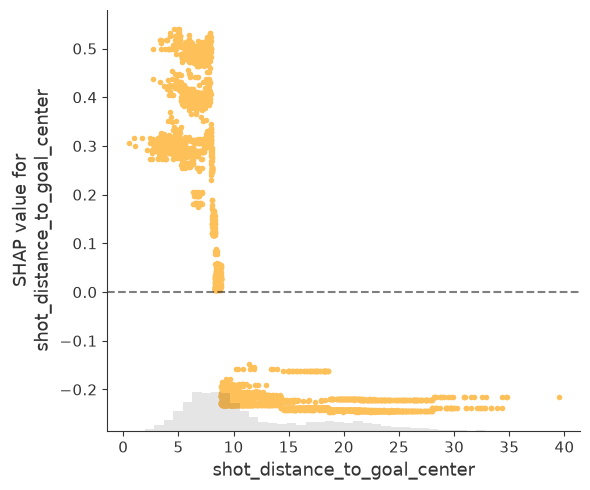

In [100]:
plot_shap_scatter(shap_values, feature="shot_distance_to_goal_center", color=COLOR_Y)

The relationship is markedly different from a smooth nonlinear curve: it resembles a sharp threshold effect rather than a gradual transition. For distances below approximately 8–9 units, the SHAP contribution is consistently positive, clustering mostly between 0.3 and 0.55, with a dense concentration of points. This indicates that being close to the centre of the goal reliably boosts predicted xG, and does so fairly uniformly across this narrow range.

Around a distance of 8–9, the SHAP value drops abruptly from strongly positive to negative, crossing zero within a very narrow band. This sharp discontinuity, rather than a smooth transition, suggests the model has learned something close to a step function for this feature, with little intermediate behavior between "close to centre" and "far from centre."

Beyond a distance of roughly 9, the SHAP values plateau at consistently negative levels, mostly between −0.15 and −0.25, and remain flat all the way out to 40. Unlike the positive region, there is little further decline as distance increases, indicating that once a shot is far from the goal centre, additional distance contributes little extra penalty to predicted xG.

The grey histogram along the bottom shows that the bulk of observations are concentrated in the 5–15 range, with a long, sparse tail extending to 40. This means the flat negative plateau at higher distances is supported by comparatively few observations, so it should be interpreted with some caution.

Overall, this dependence plot confirms `shot_distance_to_goal_center` as an influential driver of predicted xG, but its effect behaves more like a binary proximity threshold than a continuously graded relationship, with a sharp transition around 8–9 units rather than the smoother, more gradual pattern seen for `open_goal_angle`.

#### `gk_distance_to_ball`

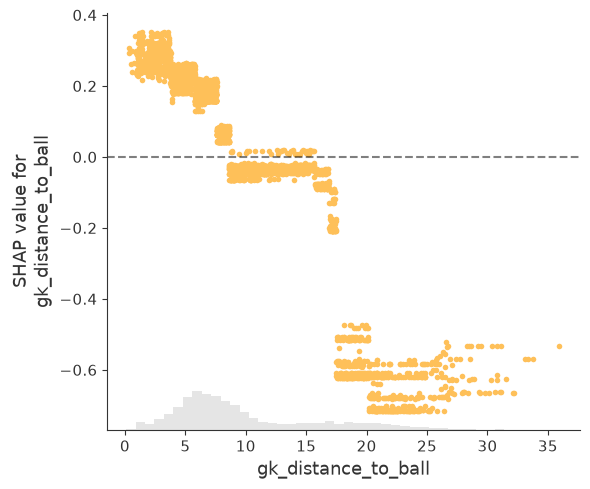

In [101]:
plot_shap_scatter(shap_values, feature="gk_distance_to_ball", color=COLOR_Y)

The relationship shows a clear multi-stage, non-monotonic pattern rather than a single smooth trend. For distances below approximately 8, the SHAP contribution is consistently positive, ranging from around 0.15 to 0.35, and gradually declines as distance increases within this band. This indicates that when the goalkeeper is very close to the ball, the model attributes a meaningful boost to predicted xG.

Between roughly 8 and 17, the SHAP values sit close to zero, mostly between −0.1 and 0.05, with a gentle downward drift as distance increases. This middle region behaves as a transitional zone, where goalkeeper distance has only a marginal effect on the prediction.

Beyond a distance of approximately 17–20, the SHAP values drop sharply to a distinctly negative band, mostly between −0.5 and −0.7, and remain flat across the remaining range out to 35. This is a considerable jump rather than a continuation of the gradual decline seen in the middle region, suggesting the model treats large goalkeeper distances as a qualitatively different regime, likely associated with long-range shots where the goalkeeper is positioned deep and detached from the play.

The grey histogram along the bottom shows that observations are concentrated in the 0–15 range, with a smaller, more dispersed cluster appearing again around 17–35. This bimodal distribution supports the idea of two distinct shot contexts rather than a single continuous relationship, and also means the negative plateau at high distances rests on a comparatively sparse set of observations.

Overall, this dependence plot confirms `gk_distance_to_ball` as an influential but non-monotonic driver of predicted xG, with three distinguishable regimes: a positive-effect zone at short distances, a near-neutral transitional zone at intermediate distances, and a sharply negative plateau at long distances, consistent with the earlier caution that this variable's effect is closely tied to shot distance and should not be read as an isolated causal relationship.

#### `defenders_within_3m`

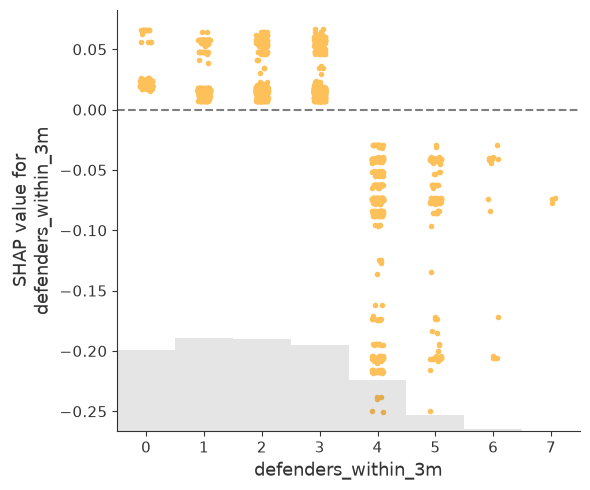

In [102]:
plot_shap_scatter(shap_values, feature="defenders_within_3m", color=COLOR_Y)

Because `defenders_within_3m` is a discrete count variable, the relationship appears as distinct vertical clusters rather than a continuous curve, but a clear threshold pattern is still visible. For counts of 0 to 3, the SHAP contribution is consistently positive, sitting mostly between 0.01 and 0.07, with similar spread across all four values. This indicates that having up to three defenders within three metres has a mildly favourable, fairly stable effect on predicted xG.

At a count of 4, the SHAP values shift abruptly to negative territory, ranging widely from about −0.02 down to −0.25. This is a sharp discontinuity rather than a gradual decline, suggesting the model treats four or more nearby defenders as a qualitatively different, high-pressure situation.

From 4 through 7, the SHAP values remain negative and show considerable spread, generally deepening in the more negative direction as the count increases, though with substantial overlap between adjacent values. This suggests that beyond the initial threshold at 4, additional defenders continue to add some incremental negative pressure, but with more variability, likely reflecting interactions with other contextual features.

The grey histogram along the bottom shows that the bulk of observations occur at counts of 0 to 3, with progressively fewer shots as the count rises to 4 and above, and very few observations at 6 or 7. This means the more extreme negative contributions at higher counts are supported by relatively limited data and should be interpreted with some caution.

Overall, this dependence plot confirms `defenders_within_3m` as a meaningful driver of predicted xG, characterised by a sharp threshold effect at four defenders rather than a smooth continuous relationship: counts below this threshold are mildly positive and stable, while counts at or above it produce a substantial and increasingly variable negative contribution, consistent with the earlier point that this variable represents immediate defensive pressure on the shooter.

### Important Interactions

#### `gk_distance_to_ball` & `shot_distance_to_goal_center`

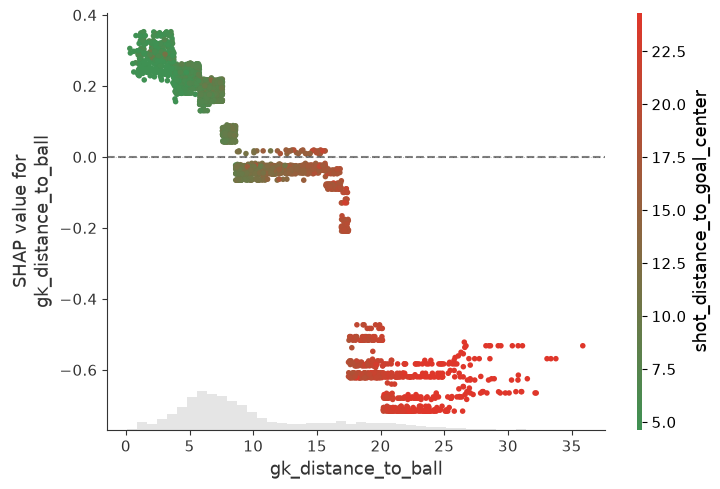

In [103]:
plot_shap_scatter_colored_by_feature(
    shap_values, feature="gk_distance_to_ball",
    color_feature="shot_distance_to_goal_center", cmap=custom_cmap_gr,
)

This plot repeats the `gk_distance_to_ball` dependence relationship, but adds `shot_distance_to_goal_center` as a colour dimension, revealing that the earlier three-stage pattern is closely tied to shot distance rather than being an independent effect. For low `gk_distance_to_ball` values (roughly 0–8), where SHAP values are positive (0.15–0.35), points are consistently green, corresponding to short `shot_distance_to_goal_center` values (below about 10). This confirms that the positive contribution at short goalkeeper distances coincides specifically with shots taken close to goal.

In the near-zero transitional band (roughly 8–17), the colour shifts to olive and orange tones, indicating intermediate `shot_distance_to_goal_center` values (around 10–17). This gradual colour transition aligns with the gradual decline in SHAP values observed in this region, suggesting the two variables move together rather than one driving the other independently.

In the sharply negative plateau (`gk_distance_to_ball` beyond roughly 17–20, SHAP values around −0.5 to −0.7), points are almost uniformly red, corresponding to large `shot_distance_to_goal_center` values (above about 17, extending past 22). This strongly supports the earlier caution that large goalkeeper distances mainly reflect long-range shots, where the goalkeeper naturally remains near goal and thus far from the ball, rather than representing an independent tactical factor.

The grey histogram along the bottom again shows most observations concentrated at low-to-moderate `gk_distance_to_ball` values, with a sparser, more scattered set of observations in the high-distance, high-shot-distance region.

Overall, this coloured dependence plot reinforces that `gk_distance_to_ball` and `shot_distance_to_goal_center` are strongly entangled: the three regimes identified previously (positive, near-neutral, and sharply negative) correspond almost one-to-one with short, medium, and long shot distances respectively. This confirms that `gk_distance_to_ball`'s apparent effect should not be interpreted as an isolated causal driver of xG, but rather as a proxy that partly encodes shot distance itself.

#### `open_goal_angle` & `shot_distance_to_goal_center`

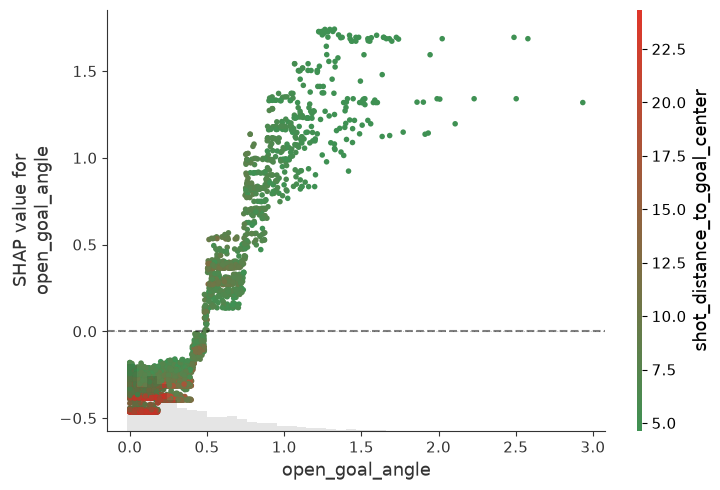

In [104]:
plot_shap_scatter_colored_by_feature(
    shap_values, feature="open_goal_angle",
    color_feature="shot_distance_to_goal_center", cmap=custom_cmap_gr,
)

This plot repeats the `open_goal_angle` dependence relationship, adding `shot_distance_to_goal_center` as a colour dimension. Unlike the previous `gk_distance_to_ball` plot, the colouring here is largely uninformative for most of the range: from an angle of roughly 0.5 upward, where SHAP values rise steeply and plateau, points are almost entirely green, indicating consistently short `shot_distance_to_goal_center` values across this entire region. This suggests that once the open-goal angle becomes moderate to large, shot distance to the centre of the goal is fairly uniform and does not meaningfully differentiate the SHAP contribution.

The colour variation is concentrated almost exclusively in the low-angle band, below approximately 0.5, where SHAP values are negative. Here, points range from green to red, with red points (`shot_distance_to_goal_center` above roughly 17–20) clustering toward the most negative SHAP values, around −0.4 to −0.5, while green points (short distances) sit somewhat higher, closer to −0.2. This indicates a modest interaction effect: among shots with narrow open-goal angles, those taken from further away receive an additional negative penalty beyond what the angle alone would suggest.

Beyond an angle of about 0.5, no such colour-based separation is visible, meaning `shot_distance_to_goal_center` adds little explanatory power once the angle itself becomes favourable. This is a notable contrast with the earlier `gk_distance_to_ball` plot, where the two variables were shown to be closely entangled across their entire range.

The grey histogram along the bottom confirms, as before, that most observations lie at low angles, so the mild interaction visible in the negative-SHAP region is based on a reasonably substantial number of points, while the plateau region remains sparser.

Overall, this coloured dependence plot suggests that `open_goal_angle` operates largely independently of `shot_distance_to_goal_center` once the angle is moderate or large, with only a limited interaction effect appearing among shots with narrow angles, where greater distance to the goal centre compounds the negative contribution.

#### `nearest_defender_2_distance` & `defenders_within_3m`

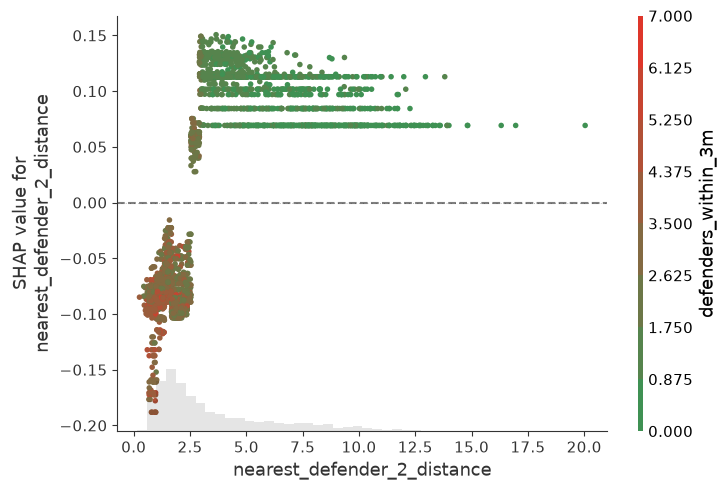

In [105]:
plot_shap_scatter_colored_by_feature(
    shap_values, feature="nearest_defender_2_distance",
    color_feature="defenders_within_3m", cmap=custom_cmap_gr,
)

This plot shows the dependence relationship for `nearest_defender_2_distance`, coloured by `defenders_within_3m`, and reveals a sharp split into two distinct clusters rather than a single continuous trend. For distances below approximately 2.5, the SHAP contribution is consistently negative, ranging mostly between −0.02 and −0.2, and the colouring here spans the full spectrum from green to red, indicating that this negative-effect zone contains shots with anywhere from 0 to 7 defenders within three metres.

Above a distance of approximately 2.5, the SHAP values jump abruptly to positive territory, mostly between 0.03 and 0.15, with a mild downward trend as distance increases further. Critically, points in this region are almost entirely green to olive, corresponding to low `defenders_within_3m` values (0 to roughly 2). This indicates that once the second-nearest defender is sufficiently far away, the shot is also reliably associated with low immediate defensive pressure, which is unsurprising given that a distant second defender leaves less room for a nearby third defender to also be close.

The interaction is most visible in the negative-SHAP cluster: within that low-distance band, redder points (higher `defenders_within_3m`, up to 6–7) tend to sit at the more negative end of the range, around −0.15 to −0.2, while greener points sit closer to −0.05. This suggests that when the second-nearest defender is already close, additional immediate pressure from other defenders compounds the negative contribution further.

The grey histogram along the bottom shows that the vast majority of observations fall below a distance of about 5, with a long, sparse tail extending to 20. This means the positive-SHAP plateau at larger distances, despite appearing visually extensive, rests on comparatively few observations at the higher end.

Overall, this coloured dependence plot confirms that `nearest_defender_2_distance` and `defenders_within_3m` are meaningfully entangled: short second-defender distances coincide with variable, often higher, immediate defender counts and consistently negative SHAP contributions, while longer distances are associated with lower immediate pressure and a shift to positive contributions, consistent with the earlier point that defender-count and defender-distance variables should be interpreted jointly rather than as isolated effects.

## Conclusion

**HistGradientBoosting** was selected as the strongest internally developed model because it offered the best balance between predictive performance, calibration, and resistance to overfitting. It achieved the lowest test log loss, the highest ROC-AUC, and a calibration slope close to the ideal value.

| Metric            | **HistGradientBoosting** | **StatsBomb** | Best point estimate      |
| ----------------- | -----------------------: | ------------: | ------------------------ |
| Log loss          |             **0.254819** |      0.257461 | **HistGradientBoosting** |
| Brier score       |                 0.069731 |  **0.069721** | Effectively identical    |
| ROC-AUC           |             **0.747365** |      0.742060 | **HistGradientBoosting** |
| Average precision |                 0.311920 |  **0.316505** | **StatsBomb**            |

Compared with **StatsBomb**, the specialized model reduced log loss by approximately 1% and improved ROC-AUC by `0.0053`. Conversely, StatsBomb obtained a marginally lower Brier score, higher average precision, lower expected calibration error, and an aggregate expected-goals estimate closer to the observed number of goals. Therefore, neither model dominated across every evaluation dimension.

Furthermore, all confidence intervals from the paired bootstrap comparison included zero. The observed differences could consequently be explained by sampling variation, and there is insufficient evidence to conclude that either model is genuinely superior. The appropriate interpretation is therefore **competitive equivalence rather than superiority**.

### Was the specialized model successful?

As a first proof of concept, the project was successful. A model developed specifically for first-phase shots following corners and indirect free kicks achieved predictive performance comparable to StatsBomb, despite being trained on fewer than 4,000 observations. This indicates that set-piece-specific information—particularly shot geometry, defensive obstruction, goalkeeper positioning, and nearby-player locations—contains meaningful predictive signal.

However, the results do not yet demonstrate that a dedicated set-piece model is consistently better than a general-purpose xG model. The current evidence is inconclusive because the differences are extremely small relative to their uncertainty. Consequently, this project supports the **viability and potential value** of specialization, but not yet a definitive performance advantage.

This distinction is important. StatsBomb's model benefits from a training base containing a very large number of shots, whereas the present model was developed using matches from only three seasons of the Portuguese First Division. Achieving comparable performance with such limited data is encouraging. With tens or hundreds of thousands of relevant set-piece observations—and potentially millions of shots from which broader contextual patterns could be learned—a specialized model may be able to identify stable relationships that cannot be estimated reliably from the current sample.

### Limitations

The main limitation is the dataset size. After applying the scope of the project, only `3,685` shots remained available. The test set contained `737` shots and only `64` goals. This produces wide confidence intervals, limits the statistical power to distinguish similar models, and makes estimates of rare situations particularly unstable.

The data also come exclusively from three seasons of a single domestic competition. The model has therefore not been tested against changes in competition quality, tactical style, data-collection conditions, or set-piece strategies outside the Portuguese First Division. Its performance cannot yet be assumed to generalize to other leagues, seasons, or football environments.

The random stratified split and cross-validation preserve the target distribution, but they do not account for the dependence between shots from the same match, team, season, or set-piece routine. Related observations may consequently appear in different folds. Similarly, the bootstrap procedure resamples individual shots and assumes that they are independent. These choices were reasonable for this initial version given the small dataset, but they may underestimate uncertainty.

The model is also deliberately narrow in scope. It covers only first-phase shots originating from corners and indirect free kicks. Throw-ins, second-phase situations, direct free kicks, penalties, and more loosely defined set-piece sequences are excluded. The conclusions therefore apply to this specific definition of a set-piece shot rather than to every dead-ball situation.

Some potentially relevant information remains unexplored. Freeze-frame features describe the moment of the shot but do not fully represent how the routine developed beforehand. Delivery type and location, movement patterns, blocking actions, possession sequences, defensive organization, and the timing of player runs may all influence chance quality. In addition, rare binary variables and partially observed freeze-frame information may be sensitive to small samples and data-collection coverage.

Finally, the calibration results should be interpreted cautiously. Although HistGradientBoosting produced an almost ideal point estimate for the calibration slope, this estimate was obtained from only 64 test goals. Confidence intervals are required before concluding that its calibration structure is reliably superior.

### Future improvements

This notebook represents the **first version** of the model. Its primary purpose is to establish a complete modeling framework and determine whether specialized set-piece xG modeling is worth pursuing. The results justify further development in the following areas:

1. **Expand the dataset**

   * Add more seasons from the Portuguese First Division.
   * Include other domestic competitions and leagues.
   * Increase the representation of rare set-piece configurations.
   * Reassess model performance as the sample grows from thousands toward tens or hundreds of thousands of observations.

2. **Introduce stronger external validation**

   * Reserve the newest season as a completely untouched temporal test set.
   * Validate the frozen model on other competitions and countries.
   * Examine whether performance remains stable across different tactical environments and data-collection periods.

3. **Account for grouped and temporal dependence**

   * Use grouped cross-validation based on `match_id`.
   * Investigate grouping by team, team-season, or competition.
   * Compare random, grouped, and time-based validation results.
   * Replace the shot-level bootstrap with a match- or team-clustered bootstrap.

4. **Extend the definition of set-piece situations**

   * Verify whether deflections and other intermediate events correctly change `set_piece_phase`.
   * Introduce phase-two shots and determine how much predictive behavior differs from phase one.
   * Reconsider shots following throw-ins when sufficient data become available.
   * Identify and exclude shots incorrectly associated with failed direct free kicks.
   * Evaluate direct free kicks separately rather than combining them with indirect routines.
   * Consider separate models for corners, indirect free kicks, throw-ins, and direct free kicks if their sample sizes become sufficient.

5. **Extract richer information from events preceding the shot**

   * Improve the current use of `shot_key_pass_id`.
   * Link the shot to the complete delivery and possession sequence.
   * Include delivery origin, destination, height, trajectory, speed, and technique.
   * Measure the elapsed time and number of actions between the restart and shot.
   * Capture first contact, second-ball situations, rebounds, flick-ons, and defensive clearances.
   * Model changes in player positions between the delivery and the shot when tracking information is available.

6. **Improve spatial and tactical features**

   * Represent goalkeeper position relative to the shot, goal, and defensive line more comprehensively.
   * Distinguish defenders who actively block the shooting lane from nearby defenders outside it.
   * Measure defensive density, line height, marking structure, and numerical superiority in relevant zones.
   * Capture attacking overloads, screens, blocking movements, and coordinated runs.
   * Develop features describing the available visible area and freeze-frame completeness.
   * Explore spatial representations based on pitch zones, geometric graphs, or player-location grids.

7. **Perform feature ablation and stability analysis**

   * Compare location-only, shot-context, freeze-frame, and complete models.
   * Quantify the incremental value of each feature group.
   * Repeat feature selection across bootstrap samples, seasons, and folds.
   * Identify features that are consistently selected rather than relying only on the final development-set fit.
   * Examine whether SHAP relationships remain stable across seasons and set-piece types.

8. **Evaluate performance in greater detail**

   * Report metrics separately for corners and indirect free kicks.
   * Examine calibration by season, competition, body part, delivery type, and probability range.
   * Add confidence intervals for calibration intercept, slope, ECE, and aggregate expected goals.
   * Evaluate model performance at match and team level, not only at shot level.
   * Compare the model with simple interpretable baselines based only on distance and angle.
   * Assess whether observed improvements translate into better player, team, and set-piece-routine evaluation.

9. **Improve probability calibration**

   * Test post-hoc calibration methods using development data only.
   * Compare Platt scaling, isotonic regression, and beta calibration.
   * Use nested or out-of-fold calibration to avoid optimistic estimates.
   * Reassess whether calibration remains necessary after substantially expanding the dataset.

10. **Investigate alternative modeling approaches**

    * Revisit logistic regression as an interpretable benchmark with nonlinear transformations and interactions.
    * Explore CatBoost, LightGBM, generalized additive models, and Bayesian hierarchical models.
    * Consider monotonic constraints for relationships that should follow known football logic.
    * With substantially more data, represent freeze frames using graph-based or deep-learning approaches.
    * Investigate hierarchical effects that allow partial pooling across seasons, competitions, and set-piece types without making the model depend excessively on specific teams or players.

11. **Strengthen deployment and reproducibility**

    * Freeze dependency versions and document the complete data-generation process.
    * Save the fitted preprocessing and prediction pipeline as a versioned model artifact.
    * Add schema validation for new shot records.
    * Monitor feature distributions, missingness, calibration, and performance over time.
    * Retrain and revalidate the model as new seasons become available.
    * Assign model and data versions to every generated `shot_set_piece_xg` value.

### Final assessment

The first version demonstrates that building a dedicated set-piece xG model is technically feasible and analytically worthwhile. It reaches approximately the same predictive level as an established general-purpose benchmark while using a much smaller and more specialized training sample. This suggests that the chosen features capture genuine aspects of set-piece chance quality.

Nevertheless, the current experiment cannot establish that specialization produces a true improvement. The available dataset is too small, too concentrated in one competition, and contains too few test goals to separate models whose performance is nearly identical. The model should therefore be regarded as a promising foundation rather than a finished solution.

The most important next step is not simply to add more complex algorithms, but to collect substantially more observations and evaluate the framework using grouped, temporal, and external validation. If the competitive performance observed here remains stable—or improves—across a much larger and more diverse dataset, there would be considerably stronger evidence that a dedicated set-piece xG model offers value beyond a general xG model.
